# Criatura Lendária - Tiamat

## Introdução

As criaturas lendárias são tarefas da matéria de "Aprendizado de Máquina" da Ilum - Escola de Ciência, ministrada pelo professor Dr. Daniel R. Cassar. Essas tarefas são desafios que envolvem a aplicação e desenvolvimento dos conceitos abordados em aula, devendo ser entregues em datas estabelecidas.

A segunda criatura lendária é o Tiamat, que envolve a busca de dados e aplicação em ao menos três algoritmos de aprendizado de máquina, desconsiderando um baseline. Deve-se comparar o desempenho desses modelos e apresentar análises de diferentes conjuntos de hiperparâmetros, utilizando a biblioteca "Optuna".

## Bibliotecas

Para organizar a realização do projeto, foram importadas as bibliotecas a seguir.

A biblioteca "statistics" será usada para fazer análise e cálculos estatísticos dos dados. A biblioteca "pandas" será usada para a manipulação e visualização dos dados. A biblioteca "numpy" teve uso em momentos de análises estatísticas. As bibliotecas "matplotlib" e "seaborn" são utilizadas para construções gráficas.

As bibliotecas "optuna" foram importadas a fim de usar o Optuna para realizar as escolhas de hiperparâmetros e redução de dimensionalidade, a fim de melhorar os modelos.

As funções importadas da biblioteca "sklearn" serão usadas para diversos fins; portanto, serão explicados nas seções em que forem utilizadas.

In [1]:
import statistics as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import optuna
import optuna.visualization as vis

from sklearn.model_selection import GroupShuffleSplit

from scipy.spatial.distance import cdist
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

from sklearn.dummy import DummyRegressor

from functools import partial
from optuna import create_study
from optuna.samplers import TPESampler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MaxAbsScaler, MinMaxScaler, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GroupKFold, cross_val_score

from sklearn.inspection import permutation_importance

## Dados

Em seguida, os dados escolhidos para ser trabalhados foram do dataset "Superconductivty Data", no qual cada linha é um material supercondutor diferente. Esse dataset, quando baixado, vem em um arquivo do tipo "ZIP", que contém um grupo de dados com propriedades físicas e químicas dos materias, chamado "train.csv", e um contendo o nome do composto e os elementos presentes nele, chamado "unique_m.csv"; ambos são do tipo "CSV". O arquivo que será usado nos algoritmos será o primeiro, contendo as propriedades dos materiais.

Esse dataset foi encontrado no repositório UCI, com dados de 21.263 supercondutores, e os dados originais vêm do banco público SuperCon do NIMS. Os dados são númericos e o único dado categórico é o nome dos compostos que fica separado das propriedades que serão usadas nos algoritmos regressores. Esse dataset não contém dados faltantes, informação presente na própria página do UCI.

In [2]:
df = pd.read_csv("train.csv")
df

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.00
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.00
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.00
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.00
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21258,4,106.957877,53.095769,82.515384,43.135565,1.177145,1.254119,146.88130,15.504479,65.764081,...,3.555556,3.223710,3.519911,1.377820,0.913658,1,2.168889,0.433013,0.496904,2.44
21259,5,92.266740,49.021367,64.812662,32.867748,1.323287,1.571630,188.38390,7.353333,69.232655,...,2.047619,2.168944,2.038991,1.594167,1.337246,1,0.904762,0.400000,0.212959,122.10
21260,2,99.663190,95.609104,99.433882,95.464320,0.690847,0.530198,13.51362,53.041104,6.756810,...,4.800000,4.472136,4.781762,0.686962,0.450561,1,3.200000,0.500000,0.400000,1.98
21261,2,99.663190,97.095602,99.433882,96.901083,0.690847,0.640883,13.51362,31.115202,6.756810,...,4.690000,4.472136,4.665819,0.686962,0.577601,1,2.210000,0.500000,0.462493,1.84


In [3]:
compostos = pd.read_csv("unique_m.csv")
compostos

,H,He,Li,Be,B,C,N,O,F,Ne,...,Au,Hg,Tl,Pb,Bi,Po,At,Rn,critical_temp,material
0,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,29.00,Ba0.2La1.8Cu1O4
1,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,26.00,Ba0.1La1.9Ag0.1Cu0.9O4
2,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,19.00,Ba0.1La1.9Cu1O4
3,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,22.00,Ba0.15La1.85Cu1O4
4,0.0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,23.00,Ba0.3La1.7Cu1O4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21258,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,2.44,Tm0.84Lu0.16Fe3Si5
21259,0.0,0,0.0,0.0,0.0,0.0,0.0,11.0,0.0,0,...,0.0,0.0,1.0,0.0,0.0,0,0,0,122.10,Tl1Ba2Ca3Cu4O11
21260,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,1.98,Nb0.8Pd0.2
21261,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,...,0.0,0.0,0.0,0.0,0.0,0,0,0,1.84,Nb0.69Pd0.31


Primeiro, deve-se extrair as primeiras informações sobre o dataset, como seu tamanho e o tipo de cada objeto.

In [4]:
print(f"Número de linhas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")
print()
print(df.dtypes)

Número de linhas: 21263
Número de colunas: 82

number_of_elements         int64
mean_atomic_mass         float64
wtd_mean_atomic_mass     float64
gmean_atomic_mass        float64
wtd_gmean_atomic_mass    float64
                          ...   
range_Valence              int64
wtd_range_Valence        float64
std_Valence              float64
wtd_std_Valence          float64
critical_temp            float64
Length: 82, dtype: object


As propriedades dos materiais presentes que serão usadas para as regressões são propriedades elementares dadas por suas informações estatísticas. 

As propriedades elementares são dados das propriedades em sí, essas são: massa atômica (atomic_mass), em unidades atômicas; primeira energia de ionização (fie), em $kJ/mol$; raio atômico (atomic_radius), em $pm$; densidade (Density), em $kg/ m^3$; afinidade eletrônica (EletronAffinity), em $kJ/mol$; calor de fusão (FusionHeat), em $kJ/mol$; condutividade térmica (ThermalConductivity), em $W/m * K$; e valência (Valence), sem unidade de medida e indo de 1 a 7.

As informações estatística são obtidos sobre cada propriedade elementar, dado que essas propriedades foram medidas experimentalmente, essas são: média aritmética (mean); média aritmética ponderada (wtd_mean); média geométrica (gmean); média geométrica ponderada (wtd_gmean); entropia (entropy); entropia ponderada (wtd_entropy); amplitude (range); amplitude ponderada (wtd_range); desvio padrão (wtd_std); e desvio padrão ponderado (wtd_std).

A coluna com o número de elementos (number_of_elements) também será usada como atributo para a regressão.

Por fim, a temperatura crítica (critical_temp), que está em $K$, será usada como target. Os atributos não dependem dessa propriedade dos materiais, assim não há vazamento pelo target.

### Definição dos atributos e do target

Foram separados e definidos quais são os atributos e qual é o target para as futuras etapas do projeto.

In [5]:
TARGET = "critical_temp"
ATRIBUTOS = [coluna for coluna in df.columns if coluna != TARGET]

### Análise dos dados

A seguir, os dados foram análisados para a verificação de se realmente não há dados faltantes, além de uma análise exploratória e estatística dos dados.

In [6]:
df.isna().sum().sort_values(ascending=False)

number_of_elements       0
mean_atomic_mass         0
wtd_mean_atomic_mass     0
gmean_atomic_mass        0
wtd_gmean_atomic_mass    0
                        ..
range_Valence            0
wtd_range_Valence        0
std_Valence              0
wtd_std_Valence          0
critical_temp            0
Length: 82, dtype: int64

Nota-se que não há dados faltantes.

A seguir, foi feita uma análise exploratória estatística dos dados a fim de obter informações sobre eles. Essa análise foi feita de forma bruta usando a função "decribe".

In [7]:
df.describe()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
count,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,...,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000,21263.000000
mean,4.115224,87.557631,72.988310,71.290627,58.539916,1.165608,1.063884,115.601251,33.225218,44.391893,...,3.153127,3.056536,3.055885,1.295682,1.052841,2.041010,1.483007,0.839342,0.673987,34.421219
std,1.439295,29.676497,33.490406,31.030272,36.651067,0.364930,0.401423,54.626887,26.967752,20.035430,...,1.191249,1.046257,1.174815,0.393155,0.380291,1.242345,0.978176,0.484676,0.455580,34.254362
min,1.000000,6.941000,6.423452,5.320573,1.960849,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000210
25%,3.000000,72.458076,52.143839,58.041225,35.248990,0.966676,0.775363,78.512902,16.824174,32.890369,...,2.116732,2.279705,2.091251,1.060857,0.775678,1.000000,0.921454,0.451754,0.306892,5.365000
50%,4.000000,84.922750,60.696571,66.361592,39.918385,1.199541,1.146783,122.906070,26.636008,45.123500,...,2.618182,2.615321,2.434057,1.368922,1.166532,2.000000,1.063077,0.800000,0.500000,20.000000
75%,5.000000,100.404410,86.103540,78.116681,73.113234,1.444537,1.359418,154.119320,38.356908,59.322812,...,4.026201,3.727919,3.914868,1.589027,1.330801,3.000000,1.918400,1.200000,1.020436,63.000000
max,9.000000,208.980400,208.980400,208.980400,208.980400,1.983797,1.958203,207.972460,205.589910,101.019700,...,7.000000,7.000000,7.000000,2.141963,1.949739,6.000000,6.992200,3.000000,3.000000,185.000000


A seguir, foram feitos gráficos para representar de forma visual as distribuições de cada um dos atributos relacionados as propriedades físicas e químicas.

In [8]:
propriedades = {
    "atomic_mass": "massa atômica",
    "fie": "primeira energia de ionização",
    "atomic_radius": "raio atômico",
    "Density": "densidade",
    "ElectronAffinity": "afinidade eletrônica",
    "FusionHeat": "calor de fusão",
    "ThermalConductivity": "condutividade térmica",
    "Valence": "valência",
}

estatisticas = {
    "mean": "Média",
    "wtd_mean": "Média ponderada",
    "gmean": "Média geométrica",
    "wtd_gmean": "Média geométrica ponderada",
    "entropy": "Entropia",
    "wtd_entropy": "Entropia ponderada",
    "range": "Amplitude",
    "wtd_range": "Amplitude ponderada",
    "std": "Desvio padrão",
    "wtd_std": "Desvio padrão ponderado",
}

colunas_esperadas = [f"{e}_{p}" for p in propriedades for e in estatisticas]
assert set(colunas_esperadas) | {"number_of_elements"} == set(ATRIBUTOS)


def grafico_distribuicoes(chave, nome_propriedade, indice):
    """Histogramas com KDE das 10 estatísticas de uma propriedade elementar."""
    figura, eixos = plt.subplots(2, 5, figsize=(20, 7.5))
    eixos = eixos.flatten()

    for eixo, (estatistica, nome_estatistica) in zip(eixos, estatisticas.items()):
        coluna = f"{estatistica}_{chave}"
        sns.histplot(df[coluna], kde=True, ax=eixo)
        eixo.set_title(nome_estatistica, fontsize=11)
        eixo.set_xlabel(coluna, fontsize=9)
        eixo.set_ylabel("Número de exemplos", fontsize=9)

    figura.suptitle(
        f"Distribuição das estatísticas de {nome_propriedade}", fontsize=14, y=1.02
    )
    figura.tight_layout()
    plt.show()

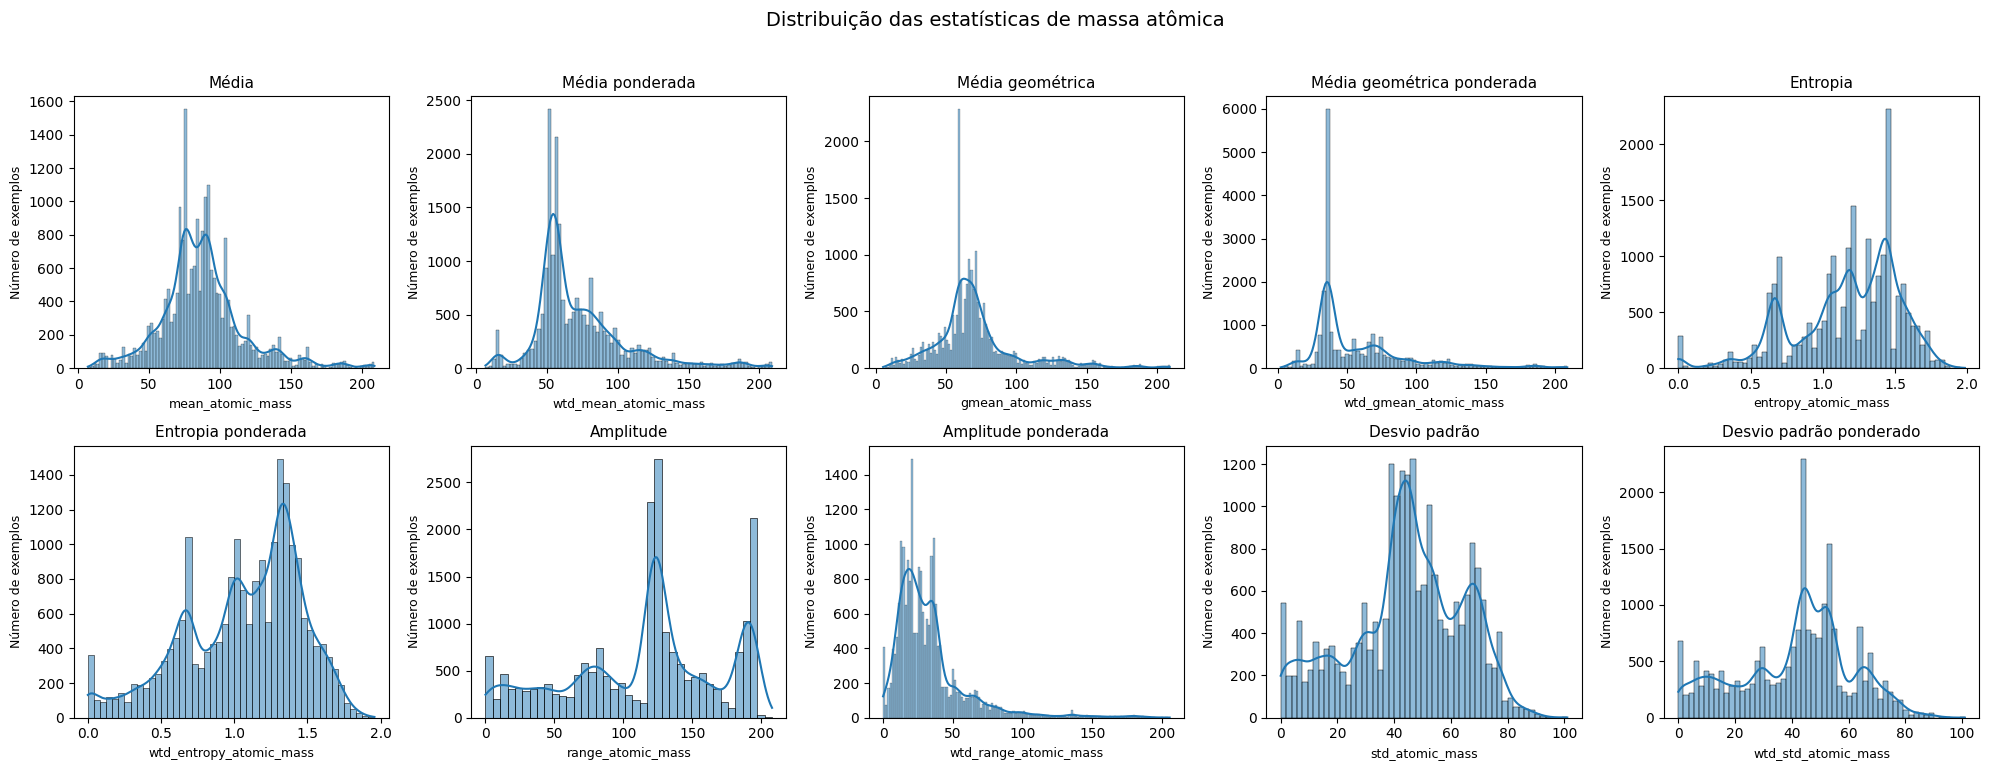

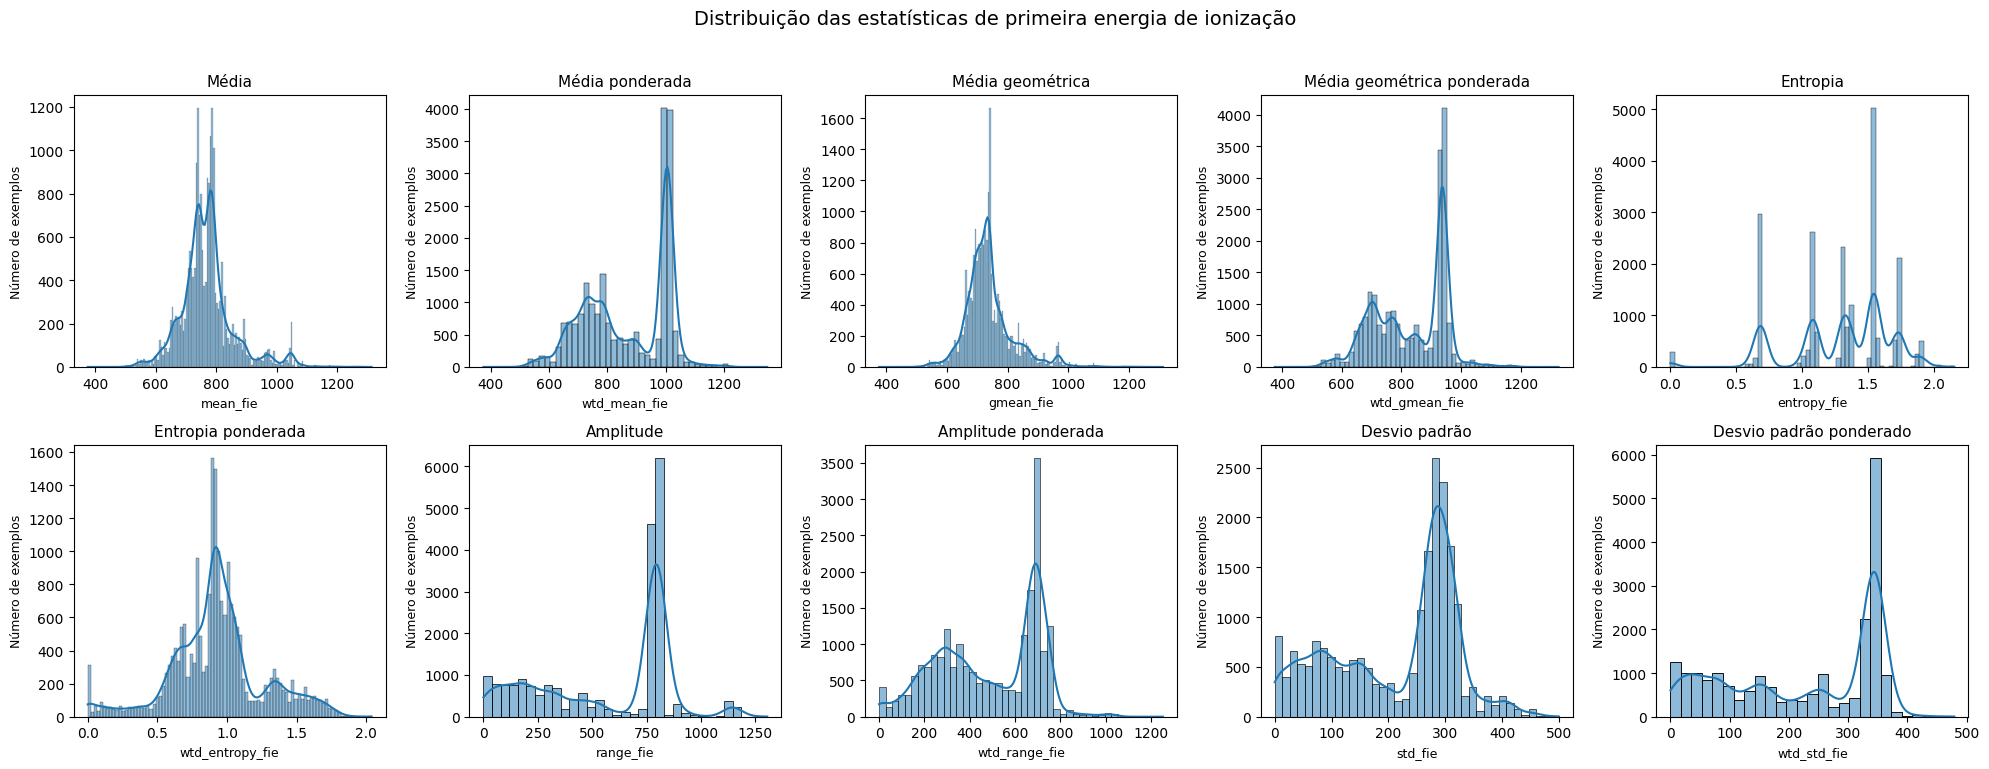

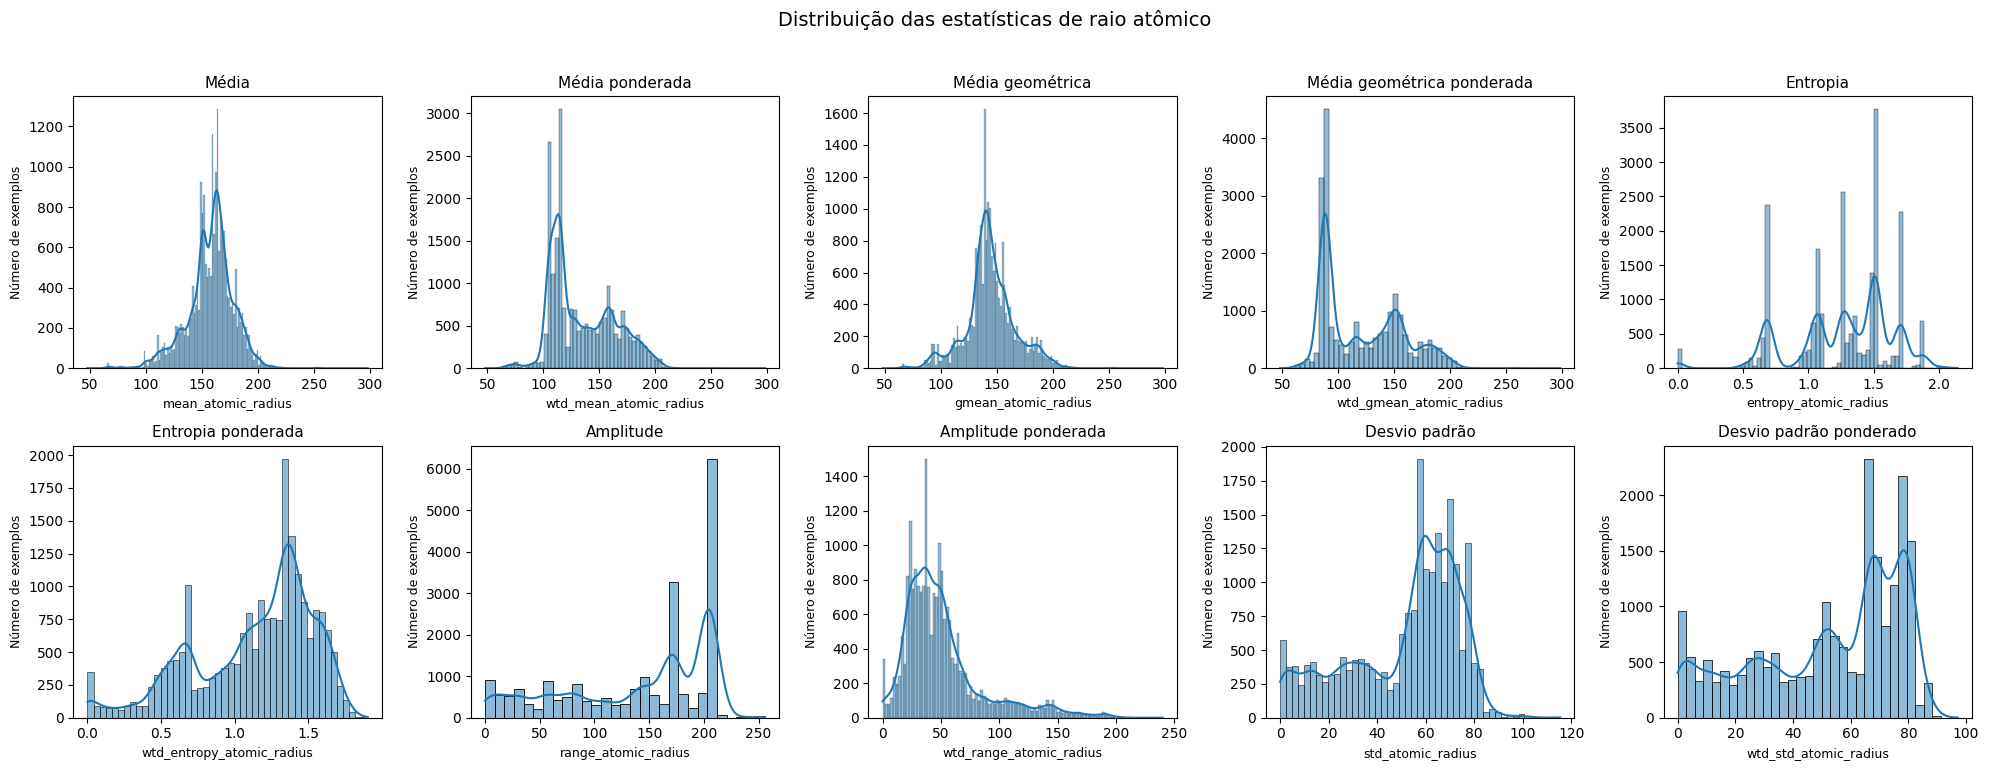

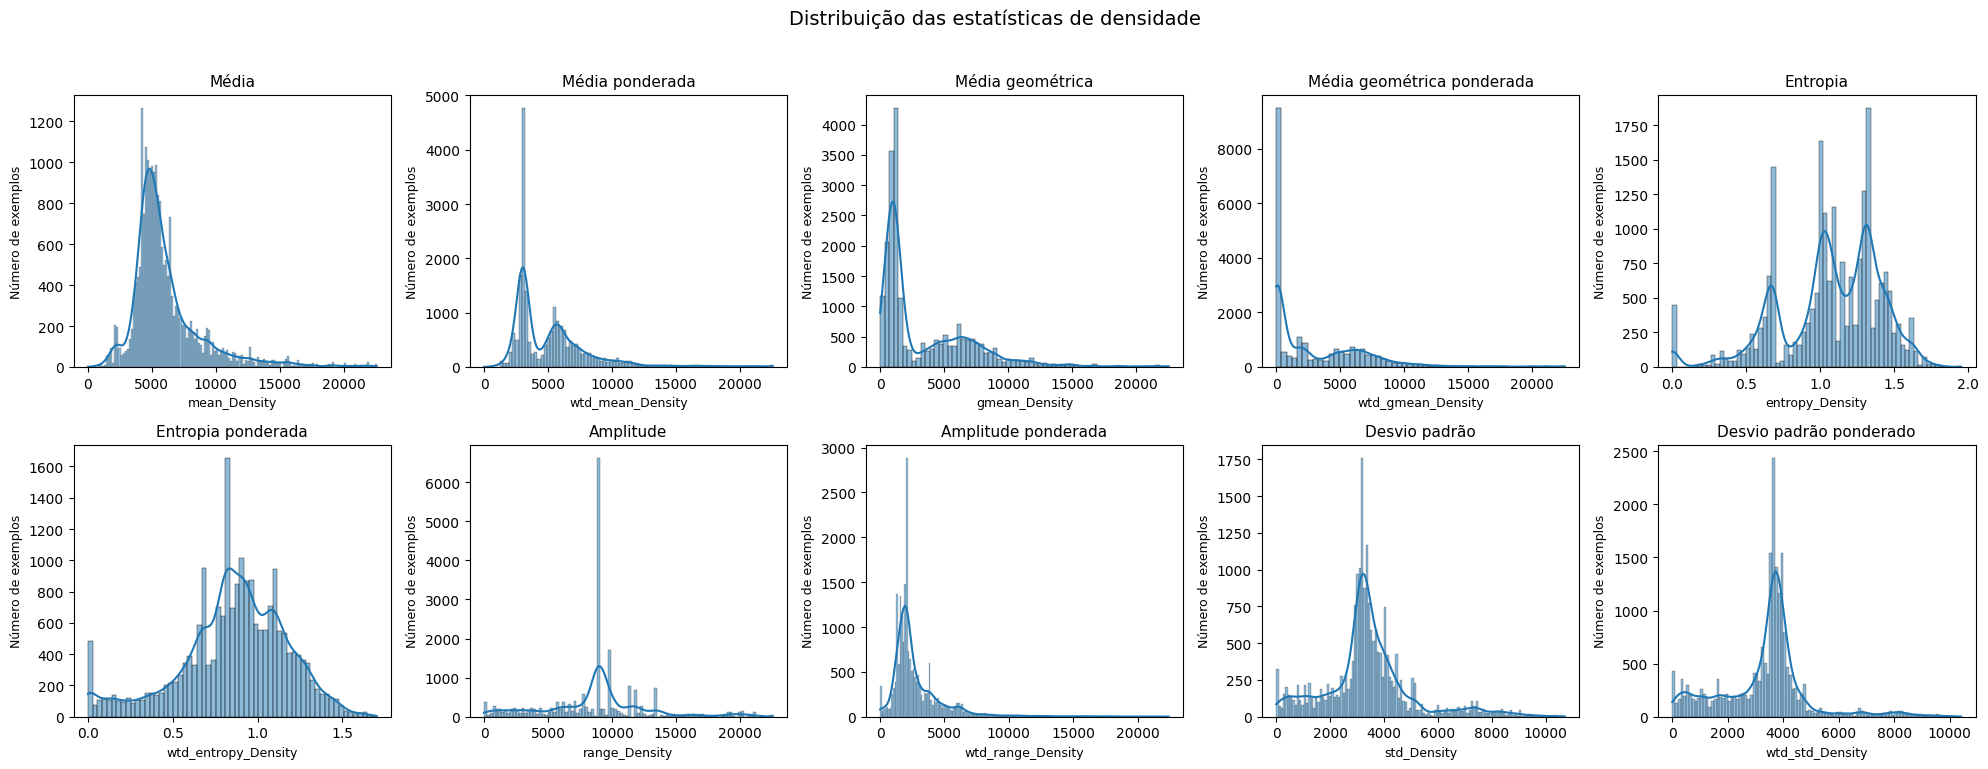

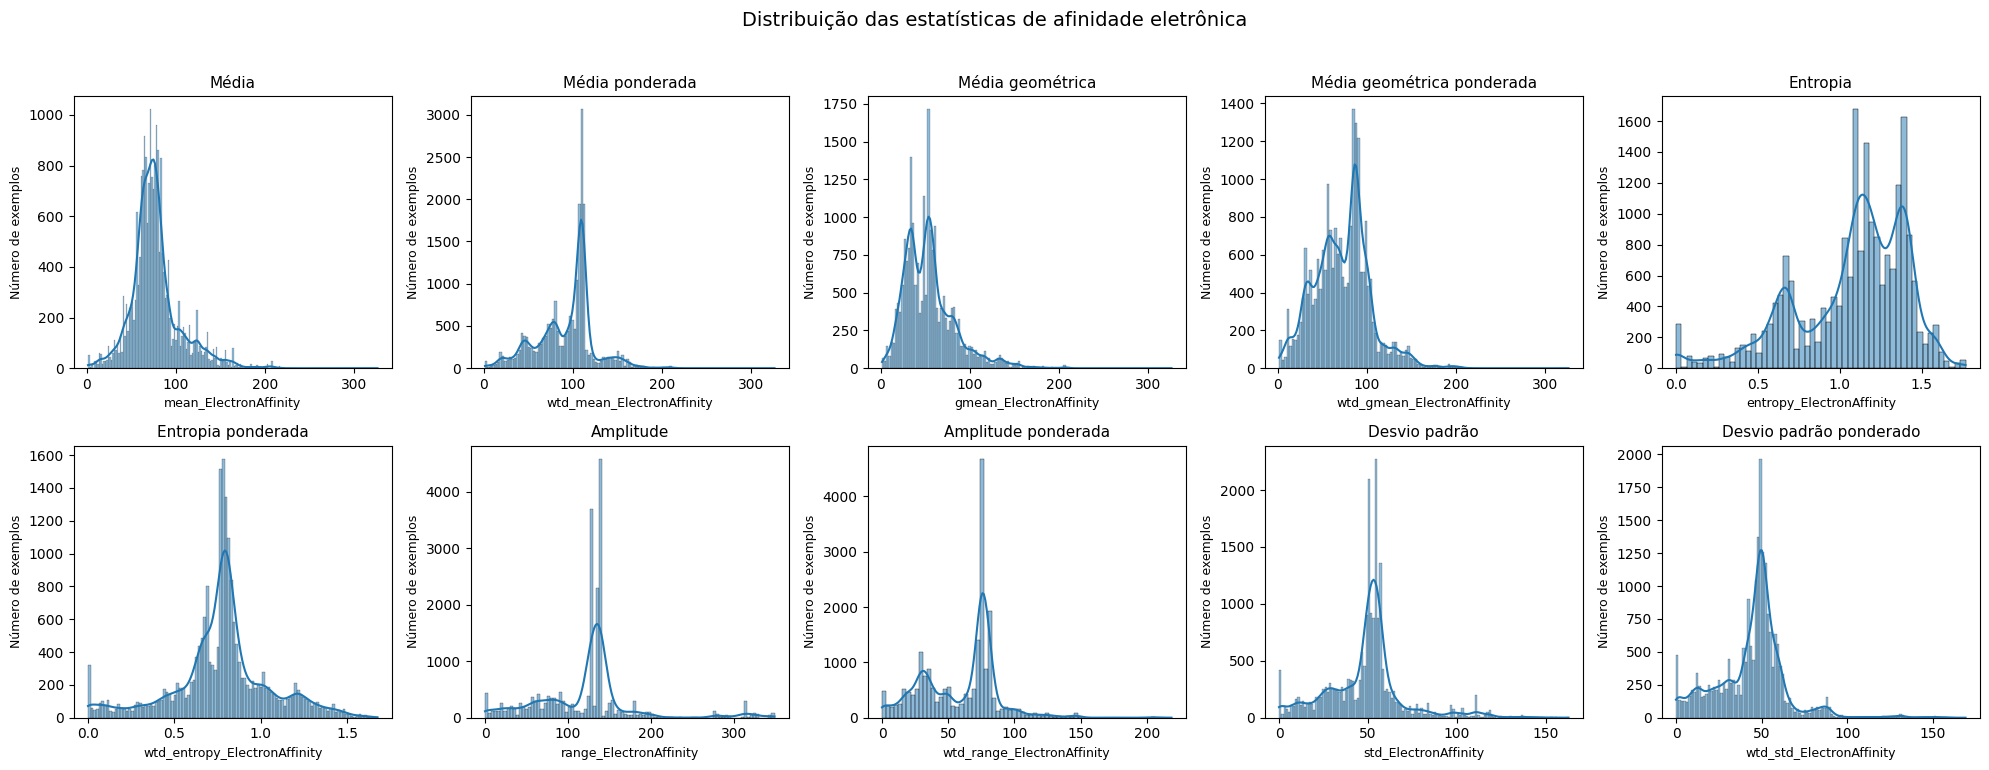

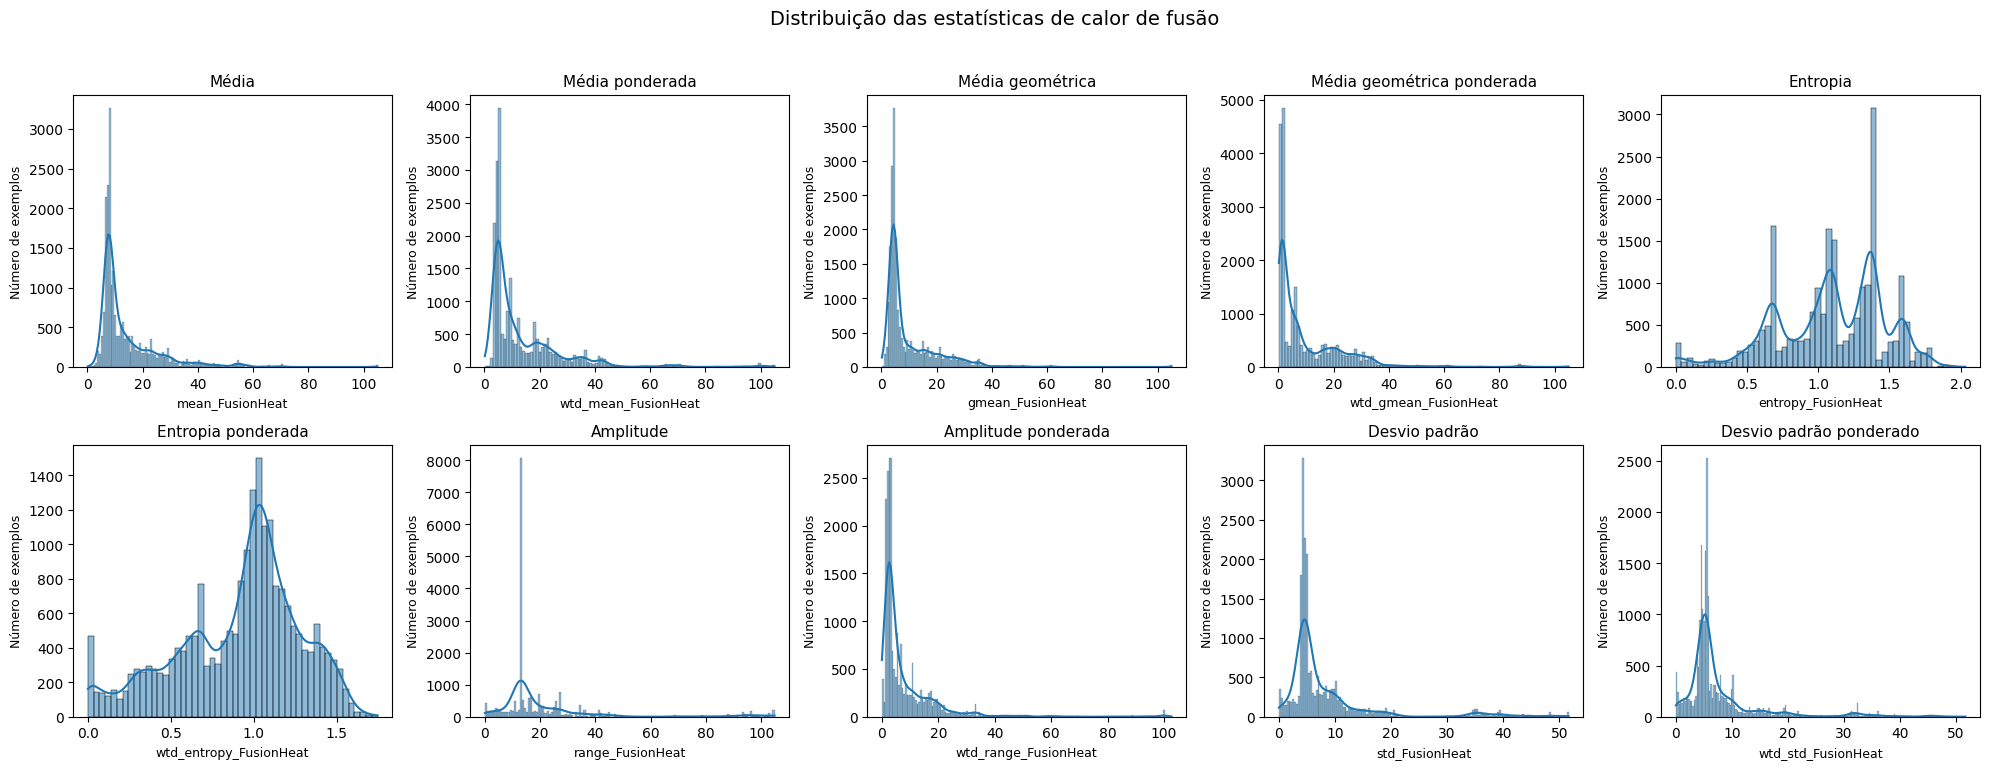

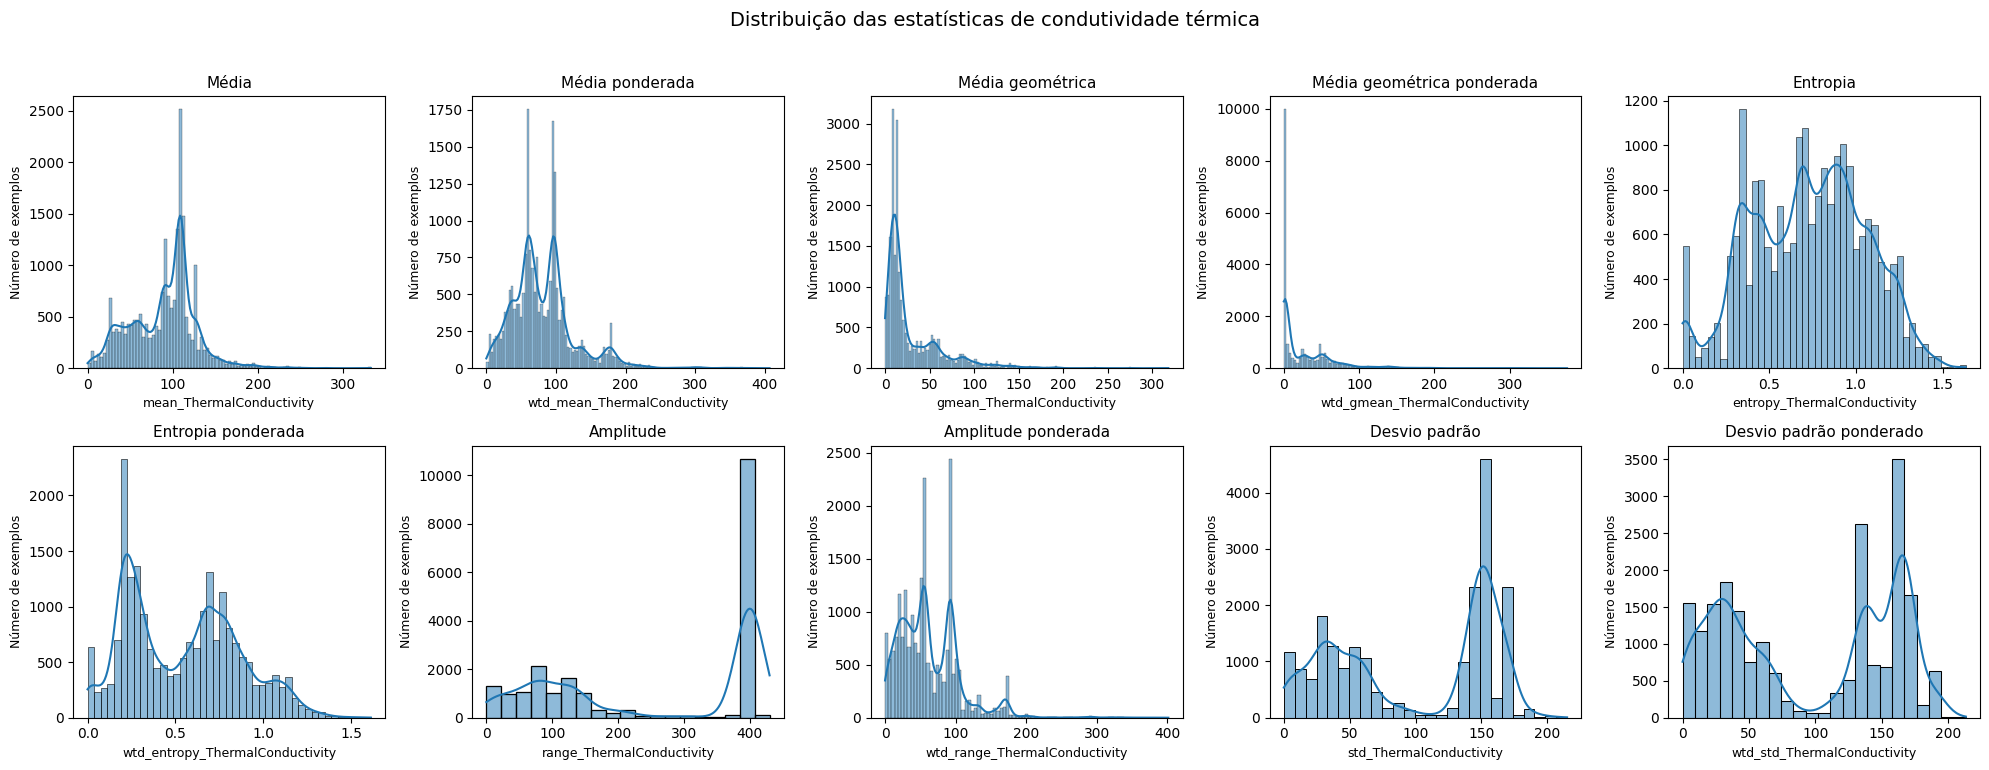

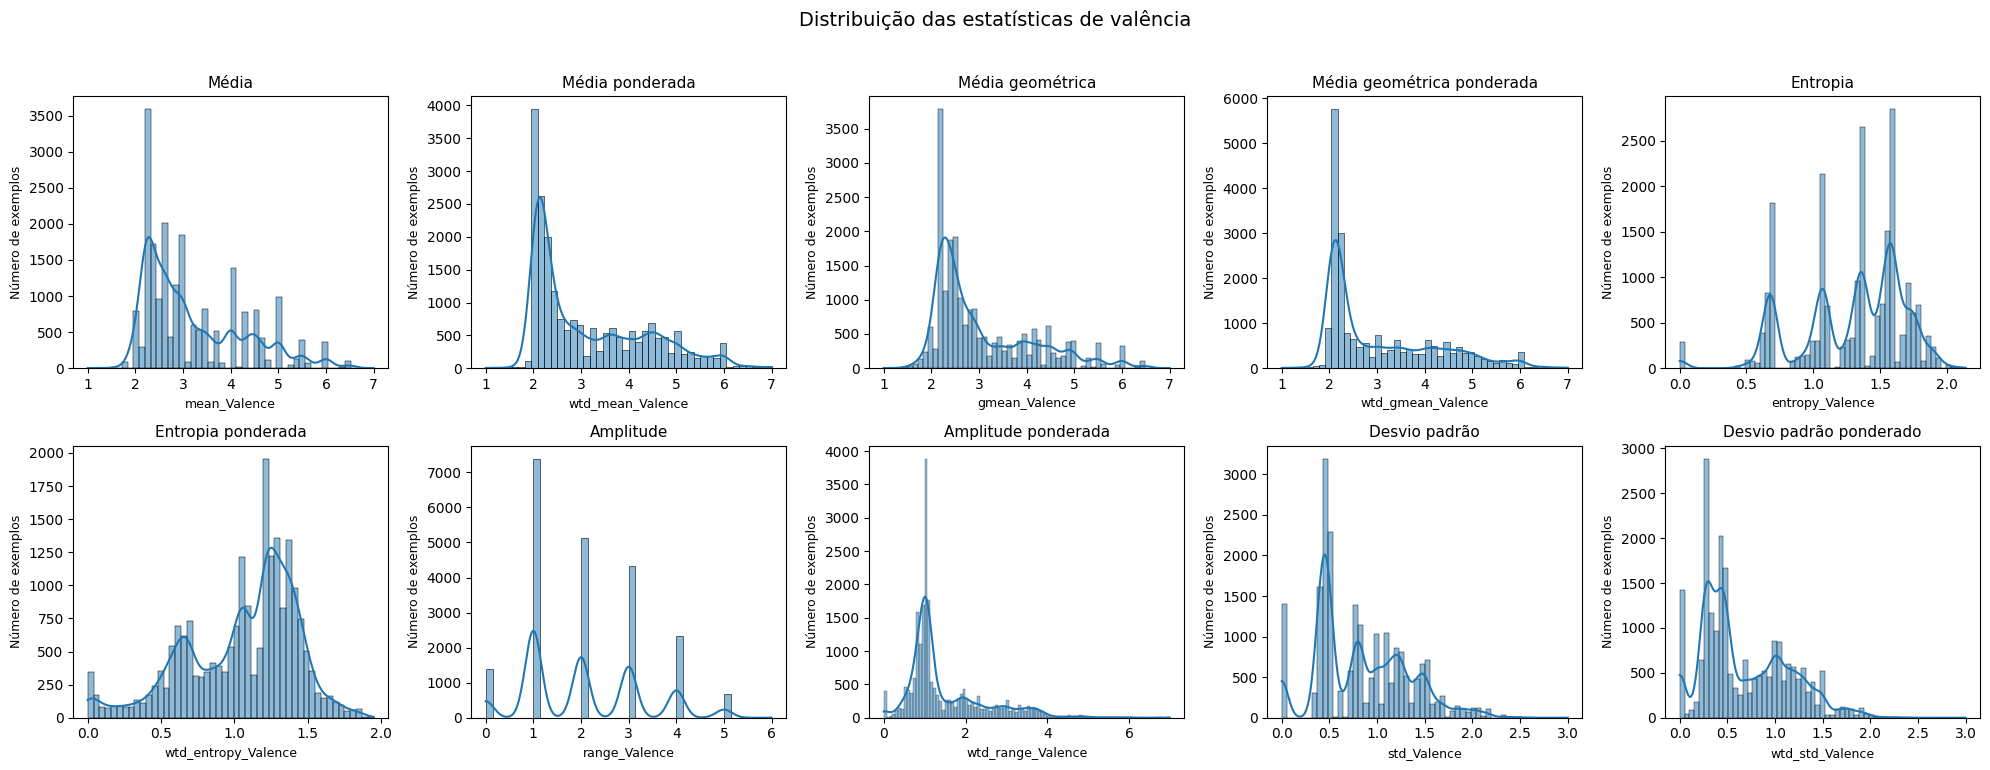

In [9]:
for indice, (chave, nome) in enumerate(propriedades.items(), start=4):
    grafico_distribuicoes(chave, nome, indice)

É notável que os atributos não seguem a distribuição normal, mas estão distriubidos de maneiras variadas e com diferentes amplitudes e desvios padrões. Também, observa-se que os atributos possuem escalas bem diferentes, portanto deve-se fazer a normalização dos dados antes de modelos que usam como base métricas de distância. Além disso, há picos em muitos gráficos, que pode ser indício de dados redundantes; principalmente por parte dos atributos que usam ponderação, pois depende apenas dos elementos que compõe o material e se repetem em materiais com os mesmos elementos.

A seguir, foi feito um gráfico para analisar a distribuição do número de elementos dos materiais, pois este é um dado numérico discreto.

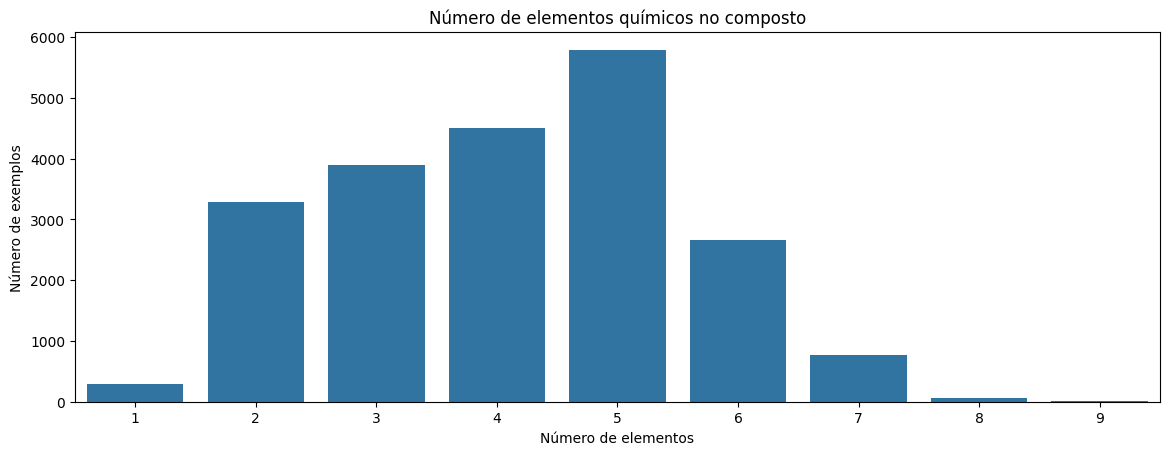

In [10]:
figura, eixos = plt.subplots(figsize=(14, 4.8))

sns.countplot(x=df["number_of_elements"])
eixos.set(
    title="Número de elementos químicos no composto",
    xlabel="Número de elementos",
    ylabel="Número de exemplos",
)

plt.show()

Percebe-se que a maioria dos compostos em análise possuem entre 3 e 5 elementos químicos diferentes.

Por fim, foi feito um gráficos para apresentar a distribuição do target.

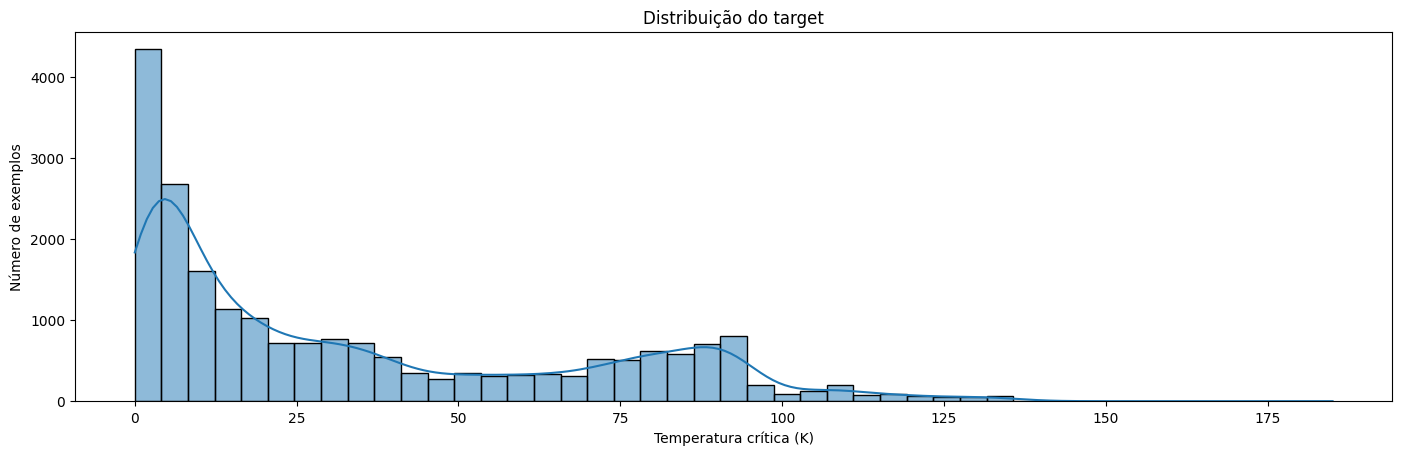

In [11]:
y = df[TARGET]
figura, eixos = plt.subplots(figsize=(17, 4.8))

sns.histplot(y, kde=True)
eixos.set(
    title="Distribuição do target",
    xlabel="Temperatura crítica (K)",
    ylabel="Número de exemplos",
)

plt.show()

Nota-se que o target possui muitos valores baixos (abaixo de 25K) e uma distribuição bem ampla.

Essa análise permite verificar quais procedências podem ser tomadas ao longo do desenvolvimento do trabalho.

### Correlação entre os dados

Por fim, para explorar os dados, foi feito o gráfico da matriz de correlação a seguir, que correlaciona os atributos entre si e com o target, permitindo a identificação de atributos com maior influência de forma visual.

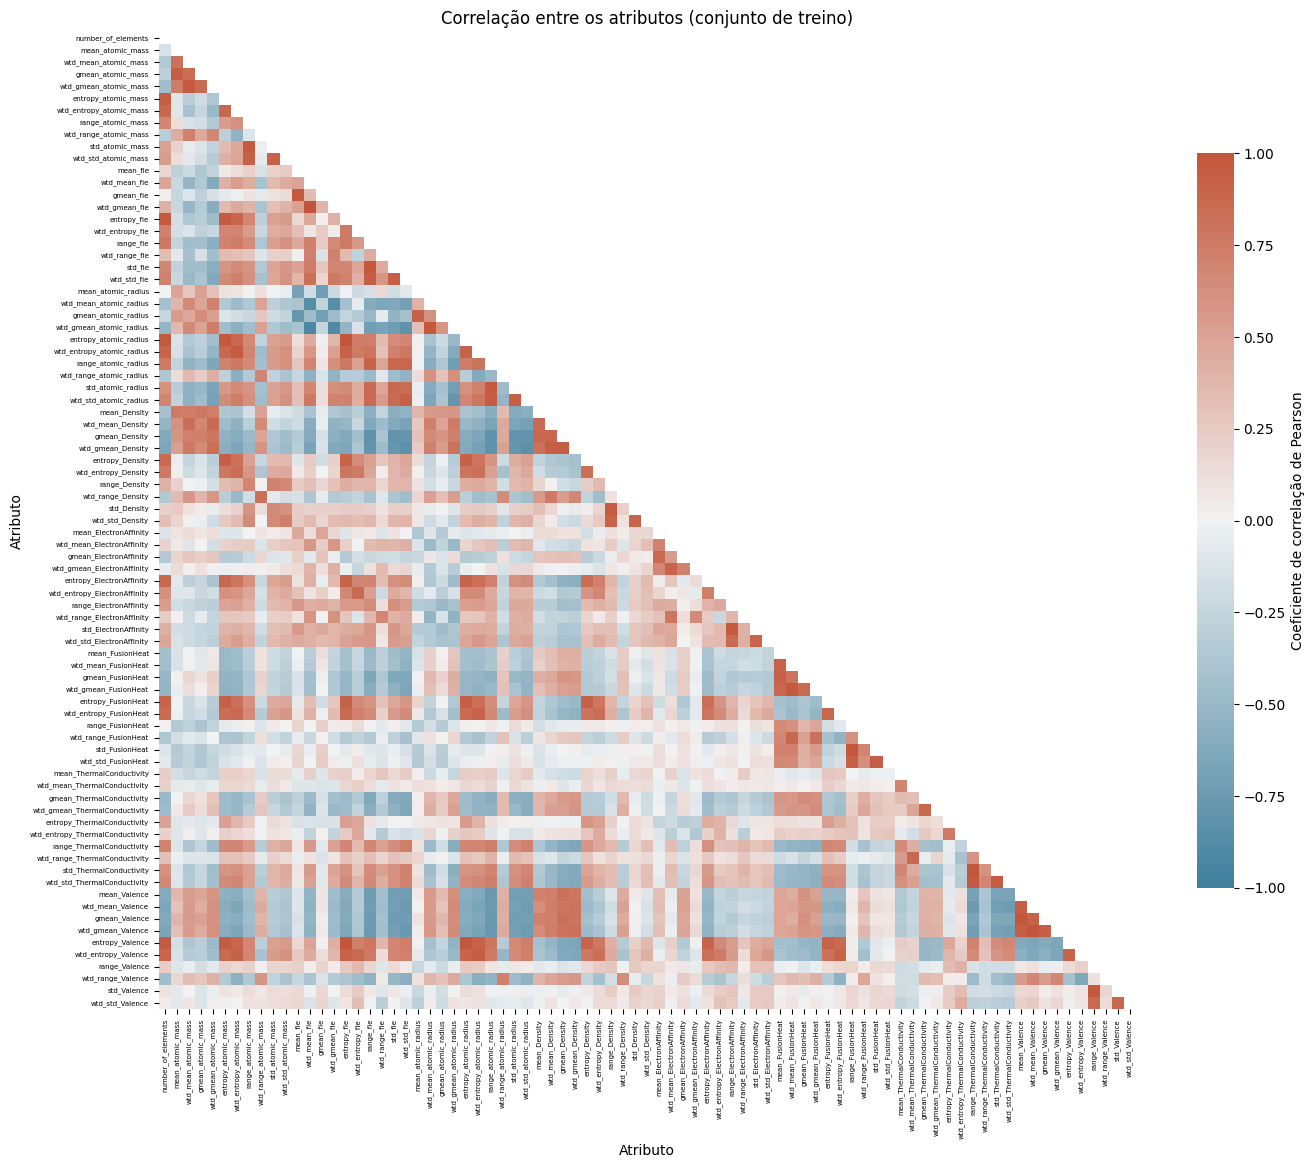

In [12]:
matriz_corr = df[ATRIBUTOS].corr()

mascara_triangulo = np.triu(np.ones_like(matriz_corr, dtype=bool))
mapa_de_cor = sns.diverging_palette(230, 20, as_cmap=True)

figura, eixo = plt.subplots(figsize=(14, 12))
sns.heatmap(
    matriz_corr,
    mask=mascara_triangulo,
    cmap=mapa_de_cor,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"shrink": 0.7, "label": "Coeficiente de correlação de Pearson"},
    ax=eixo,
)
eixo.grid(False)
eixo.tick_params(labelsize=5)
eixo.set(
    title="Correlação entre os atributos (conjunto de treino)",
    xlabel="Atributo",
    ylabel="Atributo",
)
figura.tight_layout()
plt.show()

correlacao_absoluta = matriz_corr.abs()
triangulo_superior = np.triu(np.ones(correlacao_absoluta.shape, dtype=bool), k=1)
pares = correlacao_absoluta.where(triangulo_superior).stack()

É exposto que os atributos com maior correlação positiva com a temperatura crítica são "wtd_std_ThermalConductivity", "range_ThermalConductivity", "range_atomic_radius" e "std_ThermalConductivity"; em contra partida, a correlação negativa com a temperatura crítica ocorre com três atributos, esses são "wtd_mean_Valence", "wtd_gmean_Valence" e "mean_Valence".

## Tratamento dos dados

Como próximo passo, para evitar que os algoritmos cometam certos erros, os dados foram tratados visto que pode haver a presença de dados redundantes ou quase redundantes, que podem gerar vazamento de dados.

### Dados redundantes ou quase redundantes

Primeiro, conferiu-se a presença de dados duplicados.

In [13]:
duplicados = df.duplicated().sum()
print(f'Dados duplicados: {duplicados}')

Dados duplicados: 66


Em seguida, foram tratados os dados duplicados e os quase duplicados por split agrupado. Primeiro, os valores dos atributos foram arredondados antes de formar os grupos, supondo que os valores calculados não têm a precisão apresentada nos dados. Fazer isso elimina os dados duplicados e os dados quase duplicados que podem estar presentes.

Para esse arredondamento, os atributos possuem escalas muito diferentes, portanto foi feita uma função que arredonda os dados para duas casas significativas. Com isso, pode-se separar os dados em grupos que não são redundantes ou quase redundantes, evitando o processo de vazamento de dados e overfitting.

In [14]:
def arredondar_algarismos_significativos(X, n):
    
    valores = X.to_numpy(dtype=float)
    with np.errstate(divide="ignore"):
        ordem_de_grandeza = np.floor(np.log10(np.abs(valores)))
    ordem_de_grandeza[~np.isfinite(ordem_de_grandeza)] = 0  
    passo = 10.0 ** (ordem_de_grandeza - 1)
    arredondado = np.round(valores / passo) * passo
    return pd.DataFrame(arredondado, columns=X.columns, index=X.index)

Com os dados arredondados, foi feita a separação em grupos.

In [15]:
df_arredondada = arredondar_algarismos_significativos(df[ATRIBUTOS], 2)

grupos = df_arredondada.groupby(ATRIBUTOS).ngroup()

In [16]:
print(f"Número de exemplos: {len(df)}")
print(f"Grupos únicos: {grupos.nunique()}")

Número de exemplos: 21263
Grupos únicos: 14754


### Separação dos dados de treino e teste

Definidos os grupos, os dados foram separados em dados de treino e teste usando a função "GroupShuffleSplit" da biblioteca "scikit-learn". A separção foi feita com 90% dos dados para treino e 10% para teste.

In [17]:
gss = GroupShuffleSplit(
    n_splits=1, 
    test_size=0.1, 
    random_state=8888
)

indices_treino, indices_teste = next(
    gss.split(df[ATRIBUTOS], df[TARGET], groups=grupos)
)

df_treino = df.iloc[indices_treino]
df_teste = df.iloc[indices_teste]
grupos_treino = grupos.iloc[indices_treino].to_numpy()

X_treino = df_treino[ATRIBUTOS].to_numpy()
y_treino = df_treino[TARGET].to_numpy()

X_teste = df_teste[ATRIBUTOS].to_numpy()
y_teste = df_teste[TARGET].to_numpy()

Para a separação ter ocorrido de forma correta, os grupos presentes nos dados de treino não podem ter representantes nos dados de teste. Confere-se a seguir se a separação foi bem sucedida.

In [18]:
grupos_em_comum = set(grupos.iloc[indices_treino]) & set(grupos.iloc[indices_teste])

print(f"Exemplos de treino: {len(df_treino)}")
print(f"Exemplos de teste: {len(df_teste)}")
print(f"Grupos presentes ao mesmo tempo no treino e no teste: {len(grupos_em_comum)}")

Exemplos de treino: 19076
Exemplos de teste: 2187
Grupos presentes ao mesmo tempo no treino e no teste: 0


### Checagem do split realizado

Para checar a divisão, foram comparados os histogramas das menores distâncias entre os exemplos do conjunto de treino e entre os exemplos de treino e de teste. A métrica de distância escolhida para isso foi Manhattan e os dados foram normalizados pelos mínimos e máximos por terem diferentes magnitudes usando a função "MinMaxScaler" da biblioteca "scikit-learn".

In [19]:
normalizador = MinMaxScaler()

normalizador.fit(X_treino)
X_treino_norm = normalizador.transform(X_treino)
X_teste_norm = normalizador.transform(X_teste)

In [20]:
vizinhos = NearestNeighbors(n_neighbors=1, metric="manhattan", n_jobs=-1)
vizinhos.fit(X_treino_norm)

treino_treino, _ = vizinhos.kneighbors()
treino_treino = treino_treino.ravel()

In [21]:
treino_teste = cdist(X_treino_norm, X_teste_norm, metric="cityblock").min(axis=0)

A seguir, os histogramas foram plotados e comparados.

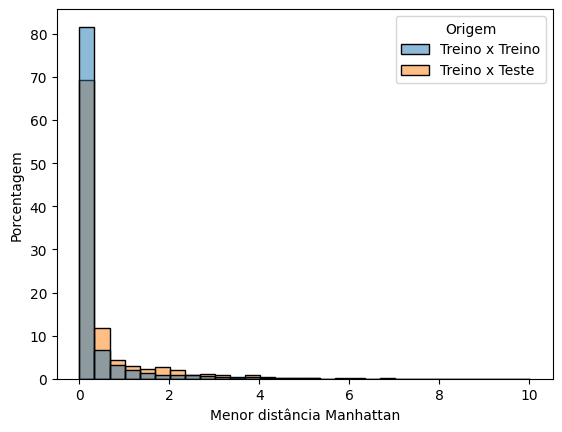

In [22]:
NUM_BINS = 30

distancias = pd.concat(
    [
        pd.DataFrame({"valor": treino_treino, "Origem": "Treino x Treino"}),
        pd.DataFrame({"valor": treino_teste, "Origem": "Treino x Teste"}),
    ],
    ignore_index=True,
)

bins = np.histogram_bin_edges(distancias["valor"], bins=NUM_BINS)

axe = sns.histplot(
    data=distancias,
    x="valor",
    hue="Origem",
    bins=bins,
    alpha=0.5,
    stat="percent",
    common_norm=False,
)

fig = axe.get_figure()
axe.set(xlabel="Menor distância Manhattan", ylabel="Porcentagem");

A fim de checar se os histogramas vieram da mesma distribuição, foi aplicado o teste de hipótese de Mann-Whitney, com nível de confiança de 95%, usando a função "mannwhitneyu" da biblioteca "scikit-learn". Se a hipótese nula for rejeitada, o split é saudável; caso contrário, pode haver vazamento de dados.

In [23]:
NIVEL_CONFIANCA = 0.95

result = mannwhitneyu(treino_treino, treino_teste, alternative="less")
pvalor = result.pvalue

print("p-valor =", pvalor)

if pvalor < 1 - NIVEL_CONFIANCA:
    print("Rejeitar H0: split saudável.")
else:
    print("Não rejeitar H0: pode haver vazamento!")

p-valor = 6.007251929835544e-191
Rejeitar H0: split saudável.


Por fim, compara-se o split realizado com agrupamento com um realizado sem agrupamento para verificar se realmente houve diferença.

p-valor = 0.2137895028770726
Não rejeitar H0: pode haver vazamento!


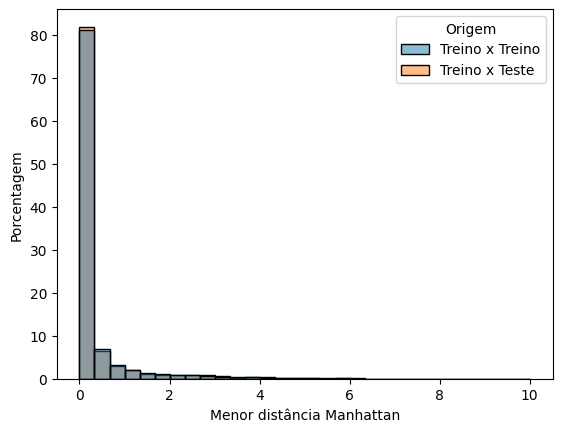

In [24]:
X_todos = df[ATRIBUTOS].to_numpy()

indices_treino_aleatorio, indices_teste_aleatorio = train_test_split(
    np.arange(len(df)), test_size=0.1, random_state=8888
)

X_treino_aleatorio = X_todos[indices_treino_aleatorio]
X_teste_aleatorio = X_todos[indices_teste_aleatorio]

normalizador_aleatorio = MinMaxScaler()
normalizador_aleatorio.fit(X_treino_aleatorio)
X_treino_aleatorio_norm = normalizador_aleatorio.transform(X_treino_aleatorio)
X_teste_aleatorio_norm = normalizador_aleatorio.transform(X_teste_aleatorio)

vizinhos_aleatorio = NearestNeighbors(n_neighbors=1, metric="manhattan", n_jobs=-1)
vizinhos_aleatorio.fit(X_treino_aleatorio_norm)

treino_treino_aleatorio, _ = vizinhos_aleatorio.kneighbors()
treino_treino_aleatorio = treino_treino_aleatorio.ravel()

treino_teste_aleatorio = cdist(
    X_treino_aleatorio_norm, X_teste_aleatorio_norm, metric="cityblock"
).min(axis=0)

distancias = pd.concat(
    [
        pd.DataFrame({"valor": treino_treino_aleatorio, "Origem": "Treino x Treino"}),
        pd.DataFrame({"valor": treino_teste_aleatorio, "Origem": "Treino x Teste"}),
    ],
    ignore_index=True,
)

bins = np.histogram_bin_edges(distancias["valor"], bins=NUM_BINS)

axe = sns.histplot(
    data=distancias,
    x="valor",
    hue="Origem",
    bins=bins,
    alpha=0.5,
    stat="percent",
    common_norm=False,
)

fig = axe.get_figure()
axe.set(xlabel="Menor distância Manhattan", ylabel="Porcentagem");

result = mannwhitneyu(treino_treino_aleatorio, treino_teste_aleatorio, alternative="less")
pvalor = result.pvalue

print("p-valor =", pvalor)

if pvalor < 1 - NIVEL_CONFIANCA:
    print("Rejeitar H0: split saudável.")
else:
    print("Não rejeitar H0: pode haver vazamento!")

Percebe-se que, caso a técnica da separação em grupos não fosse usada, os modelos sofreriam com vazamento de dados e haveria overfitting.

## Métrica de desempenho

A métrica de desempenho escolhida para analisar os modelos foi a raíz do erro quadrático médio (RMSE), pois este está na mesma unidade do target, em Kelvin. O RMSE foi calculado com a função "root_mean_squared_error" da biblioteca "scikit-learn".

## Dados para a modelagem

Para a otimização de hiperparâmetros, o conjunto de treino foi dividido em treino, com 80% dos dados, e validação, com 20%; novamente por grupos para evitar vazamento.

Como o conjunto de dados é grande, foi usado o método da separação em 3 partes: treino, validação e teste; esse método é indicado quando a validação cruzada é custosa demais. O conjunto de teste não é usado em nenhuma etapa da otimização nem na escolha do modelo, que é feita pela validação cruzada. Com isso, a avaliação de cada modelo é com base no RMSE dos dados de validação.

In [25]:
group_shuffle_split = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=8888
)

indices_treino_, indices_val = next(
    group_shuffle_split.split(X_treino, y_treino, groups=grupos_treino)
)

X_treino_, y_treino_ = X_treino[indices_treino_], y_treino[indices_treino_]
X_val, y_val = X_treino[indices_val], y_treino[indices_val]

In [26]:
print(f"Exemplos de treino: {len(X_treino_)}")
print(f"Exemplos de validação: {len(X_val)}")

Exemplos de treino: 15306
Exemplos de validação: 3770


## Preparo para a otimização com o Optuna

Para a otimização dos hiperparâmetros dos modelos, o módulo Optuna foi usado. Abaixo, também foram definidos os normalizadores que serão usados para normalizar os atributos no momento de execução dos modelos.

Esses foram definidos previamente aqui para serem usados em cada um dos modelos posteriormente.

In [27]:
warnings.filterwarnings("ignore", module="tqdm")

optuna.logging.set_verbosity(optuna.logging.ERROR)
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

NORMALIZADORES = {
    "padrao": StandardScaler,
    "minmax": MinMaxScaler,
    "maxabs": MaxAbsScaler,
}

Em seguida, foram definidas algumas funções auxiliares: a função "avalia_treino_validacao" treina o modelos e calcula o RMSE no treino e na validação; "escolher_normalizador" permite o Optuna escolher um normalizador, ou não escolher nenhum; a "funcao_objetivo" cria a Função Objetivo do Optuna, que nesse caso é o RMSE no conjunto de validação; a função "cria_estudo" cria o estudo que será feito; "trials_avaliados" mostra quais foram os trials avaliados no estudo; "num_conjuntos_distintos" retorna quantos conjuntos distintos de hiperparâmetros foram testados; "otimiza" roda a otimização com o Optuna até que seja testado o número de conjuntos de hiperparâmetros escolhido; "resumo_do_estudo" faz um resumo com os resultados numéricos obtidos no estudo; e, por fim, "mostra_resultados" imprime o melhor trial e mostra o histórico e a importância dos hiperparâmetros.

In [28]:
RESULTADOS_PADRAO = {}


def avalia_treino_validacao(modelo):
    modelo.fit(X_treino_, y_treino_)
    RMSE_treino = root_mean_squared_error(y_treino_, modelo.predict(X_treino_))
    RMSE_val = root_mean_squared_error(y_val, modelo.predict(X_val))
    return RMSE_treino, RMSE_val


def escolher_normalizador(trial):
    opcoes = list(NORMALIZADORES) + ["nenhum"]
    nome = trial.suggest_categorical("normalizador", opcoes)
    return None if nome == "nenhum" else NORMALIZADORES[nome]()


def funcao_objetivo(trial, cria_instancia_modelo, X_treino, y_treino, X_val, y_val):
    modelo = cria_instancia_modelo(trial)

    for anterior in trial.study.trials:
        if anterior.value is not None and anterior.params == trial.params:
            trial.set_user_attr("duplicado", True)
            return anterior.value

    modelo.fit(X_treino, y_treino)
    y_previsto = modelo.predict(X_val)

    return root_mean_squared_error(y_val, y_previsto)
    

def cria_estudo(nome_do_estudo):
    return create_study(
        direction="minimize",
        study_name=nome_do_estudo,
        load_if_exists=True,
        sampler=TPESampler(multivariate=True, seed=8888),
    )


def trials_avaliados(estudo):
    return [t for t in estudo.trials if t.value is not None]


def num_conjuntos_distintos(estudo):
    return len({tuple(sorted(t.params.items())) for t in trials_avaliados(estudo)})
    

def otimiza(estudo, cria_instancia_modelo, num_conjuntos=100):
    funcao_objetivo_parcial = partial(
        funcao_objetivo,
        cria_instancia_modelo=cria_instancia_modelo,
        X_treino=X_treino_,
        y_treino=y_treino_,
        X_val=X_val,
        y_val=y_val,
    )
    while (faltam := num_conjuntos - num_conjuntos_distintos(estudo)) > 0:
        estudo.optimize(funcao_objetivo_parcial, n_trials=faltam)


def resumo_do_estudo(estudo):
    avaliados = trials_avaliados(estudo)
    novos = [t for t in avaliados if not t.user_attrs.get("duplicado")]
    return {
        "Tentativas": len(avaliados),
        "Conjuntos distintos": num_conjuntos_distintos(estudo),
        "Melhor RMSE de validação (K)": estudo.best_value,
        "Tempo de otimização (min)": sum(t.duration.total_seconds() for t in novos) / 60,
    }


def mostra_resultados(estudo):
    resumo = resumo_do_estudo(estudo)
    print(f"Tentativas realizadas: {resumo['Tentativas']}")
    print(f"Conjuntos de hiperparâmetros distintos: {resumo['Conjuntos distintos']}")
    print(f"Tempo de otimização: {resumo['Tempo de otimização (min)']:.1f} min")
    print()
    melhor_trial = estudo.best_trial
    print(f"Número do melhor trial: {melhor_trial.number}")
    print(f"RMSE de validação do melhor trial: {melhor_trial.value:.3f} K")
    print("Parâmetros do melhor trial:")
    for nome, valor in melhor_trial.params.items():
        print(f"  {nome}: {valor}")

    display(vis.plot_optimization_history(estudo))
    try:
        display(vis.plot_param_importances(estudo))
    except Exception as erro:
        print(f"Não foi possível calcular a importância dos hiperparâmetros: {erro}")

Além disso, para possíveis reduções de dimensionalidade e otimização dos modelos, foi definida a função auxiliar "cria_etapas_pca" que difine se o Optuna escolhe usar PCA e, caso use, o normalizador e o número de componentes.

In [29]:
def cria_etapas_pca(trial):
    if not trial.suggest_categorical("usar_pca", [True, False]):
        return []

    etapas = []
    normalizador = escolher_normalizador(trial)
    if normalizador is not None:
        etapas.append(normalizador)

    num_componentes = trial.suggest_int("num_componentes", 1, len(ATRIBUTOS))
    etapas.append(PCA(n_components=num_componentes, random_state=8888))
    return etapas

Com essas funções definidas para o Optuna, os modelos foram sendo feitos e otimizados pelo Optuna.

## Modelo baseline

O modelos baseline é o mais simples possível, prevendo sempre a média do target do conjunto de treino. Ele foi usado neste projeto com o objetivo de servir de base para comparações.

### Treino e validação

O baseline não usa os atributos, então não precisa de normalização nem de PCA, e não tem hiperparâmetros para o Optuna otimizar. A célula abaixo treina o baseline com os dados de treino e calcula o RMSE no treino e na validação.

Ele foi feito com o uso da função "DummyRegressor" do "scikit-learn".

In [30]:
baseline = DummyRegressor(strategy="mean")

In [31]:
RMSE_treino, RMSE_val = avalia_treino_validacao(baseline)
RESULTADOS_PADRAO["Baseline (média)"] = (RMSE_treino, RMSE_val)

print(f"Média do target no treino: {baseline.constant_[0][0]:.2f} K")
print(f"RMSE no treino: {RMSE_treino:.2f} K")
print(f"RMSE na validação: {RMSE_val:.2f} K")

Média do target no treino: 34.24 K
RMSE no treino: 34.02 K
RMSE na validação: 34.83 K


O baseline prevê 34,24 K para todos os exemplos e tem RMSE de 34,02 K no treino e de 34,83 K na validação. O erro do baseline é muito alto; portanto, todo modelo com desempenho menor que o do baseline é ruim.

## Modelo de regressão linear

A regressão linear múltipla modela o target como uma combinação linear dos atributos, com coeficientes ajustados pelo método dos mínimos quadrados, que minimiza o erro quadrático nos dados de treino.

A regressão linear não tem hiperparâmetros relevantes, então o espaço de busca deste modelo vem do pré-processamento (normalização e redução de dimensionalidade com a PCA).

### Definição do modelo

Em teoria, o ajuste da regressão linear por mínimos quadrados não depende da escala dos atributos, normalizar apenas reescala os coeficientes. Por isso, a célula abaixo compara a regressão linear com e sem normalização padrão para verificar se isso se confirma. Mesmo assim, o normalizador continua sendo um hiperparâmetro do Optuna, pois ele passa a fazer diferença quando a PCA é usada.

Os modelos de regressão linear foram feitos com o uso da função "LinearRegression" do "scikit-learn".

In [32]:
modelos_lineares = {
    "Regressão linear": LinearRegression(),
    "Regressão linear com normalização padrão": make_pipeline(StandardScaler(), LinearRegression()),
}

In [33]:
for nome, modelo in modelos_lineares.items():
    RMSE_treino, RMSE_val = avalia_treino_validacao(modelo)
    print(f"{nome}: RMSE no treino = {RMSE_treino:.2f} K | RMSE na validação = {RMSE_val:.2f} K")

RESULTADOS_PADRAO["Regressão linear"] = avalia_treino_validacao(modelos_lineares["Regressão linear"])

Regressão linear: RMSE no treino = 17.45 K | RMSE na validação = 18.07 K
Regressão linear com normalização padrão: RMSE no treino = 17.45 K | RMSE na validação = 18.07 K


A regressão linear teve RMSE de 17,45 K no treino e de 18,07 K na validação, tanto sem normalizar quanto com a normalização padrão. Nota-se erros bem abaixo do baseline, cerca de metade do erro. Porém, o RMSE já é alto no próprio treino, o que indica que o modelo linear é simples demais para o problema.

### Otimização de hiperparâmetros com o Optuna

Os hiperparâmetros escolhidos para o modelo de regressão linear foram o tipo de normalização, o uso ou não de PCA e o número de componentes.

In [34]:
def cria_modelo_linear(trial):
    etapas = []

    normalizador = escolher_normalizador(trial)
    if normalizador is not None:
        etapas.append(normalizador)

    if trial.suggest_categorical("usar_pca", [True, False]):
        num_componentes = trial.suggest_int("num_componentes", 1, len(ATRIBUTOS))
        etapas.append(PCA(n_components=num_componentes, random_state=8888))

    etapas.append(LinearRegression())
    return make_pipeline(*etapas)

Tentativas realizadas: 2372
Conjuntos de hiperparâmetros distintos: 100
Tempo de otimização: 0.3 min

Número do melhor trial: 0
RMSE de validação do melhor trial: 18.070 K
Parâmetros do melhor trial:
  normalizador: nenhum
  usar_pca: False


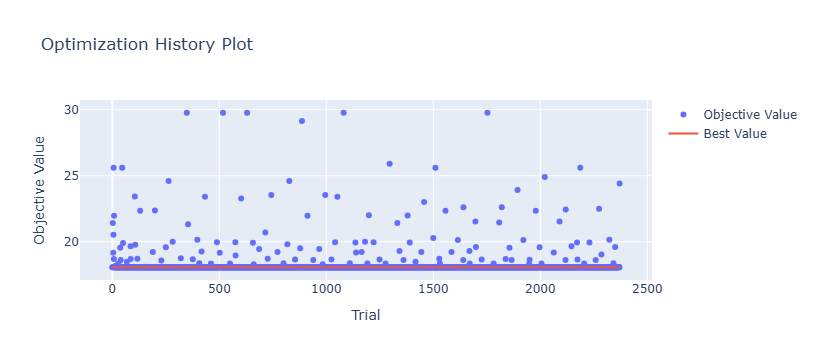

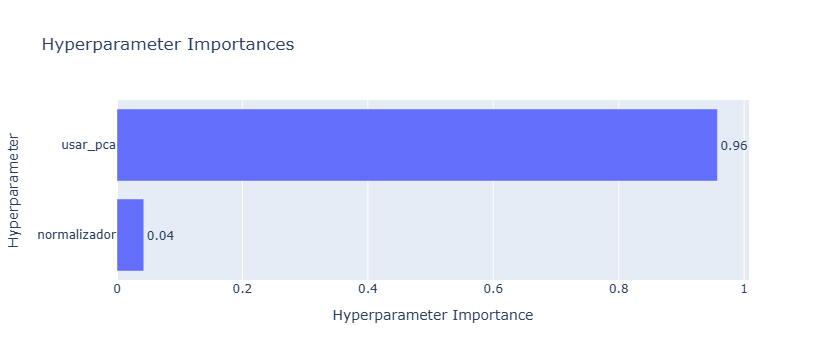

In [35]:
nome_estudo_linear = "regressao_linear"

estudo_linear = cria_estudo(nome_estudo_linear)

if len(estudo_linear.trials) == 0:
    estudo_linear.enqueue_trial({"normalizador": "nenhum", "usar_pca": False})
    estudo_linear.enqueue_trial({"normalizador": "padrao", "usar_pca": False})
    estudo_linear.enqueue_trial({"normalizador": "padrao", "usar_pca": True, "num_componentes": 20})

otimiza(estudo_linear, cria_modelo_linear)
mostra_resultados(estudo_linear)

Foram feitas 2372 tentativas. Nisso, o melhor conjunto de hiperparâmetros não usa nenhum normalizador e não usa a PCA, com um RMSE de 18.07K. O hiperparâmetro com maior importância é o uso ou não de PCA. 

Com esses resultados, nota-se que, para a regressão linear, a otimização não é benéfica, gerando apenas custo computacional.

## Modelo de regressão Polinomial

A regressão polinomial é uma regressão linear aplicada a atributos polinomiais; na qual a partir dos atributos originais, são criadas potências e produtos entre eles até um grau escolhido, e uma regressão linear é ajustada a esses novos atributos.

### Definição do modelo

O número de atributos polinomiais cresce muito rapidamente com o número de atributos de entrada e com o grau; com os 81 atributos originais, até o grau 2 já gera milhares de atributos, o que é inviável com 15 mil exemplos de treino. Por isso, na regressão polinomial, a PCA é aplicada antes do polinômio, reduzindo o número de atributos de entrada, e o número de componentes principais é um hiperparâmetro do Optuna. A normalização também é feita, e o normalizador também é escolhido pelo Optuna.

Aqui, o modelo foi treinado com o grau do polinomio sendo 2, a normalização feita foi a padrão e a PCA feita foi com 10 componentes. Esses valores foram escolhidos como referência para treinar o modelo.

Esse modelo foi feito com o uso da função "PolynomialFeatures" da biblioteca "scikit-learn".

In [36]:
GRAU_POLINOMIO = 2

modelo_polinomial = make_pipeline(
    StandardScaler(),
    PCA(10, random_state=8888),
    PolynomialFeatures(GRAU_POLINOMIO, include_bias=False),
    LinearRegression(),
)

### Avaliação

Em seguida, o modelo foi avaliado nos conjuntos de treino e de validação.

In [37]:
RMSE_treino, RMSE_val = avalia_treino_validacao(modelo_polinomial)
RESULTADOS_PADRAO["Regressão polinomial"] = (RMSE_treino, RMSE_val)

print(f"Número de atributos polinomiais: {modelo_polinomial[-2].n_output_features_}")
print(f"RMSE no treino: {RMSE_treino:.2f} K")
print(f"RMSE na validação: {RMSE_val:.2f} K")

Número de atributos polinomiais: 65
RMSE no treino: 17.97 K
RMSE na validação: 18.92 K


Essa avaliação mostra que o modelo de regressão polinomial, com os valores de referência escolhidos para os hiperparâmetros, possui RMSE de !7.97K no conjunto de treino e de 18.92K no conjunto de validação; sendo pior que a regressão linear.

### Otimização de hiperparâmetros com o Optuna

Os hiperparâmetros escolhidos para o modelo polinomial foram o tipo de normalização, o grau do polinômio (de 2 a 4) e o número de componentes do polinômio, sendo esse último de 2 a 40 para polinômio do segundo grau, 2 a 15 para polinômio do terceiro grau e 2 a 8 para polinômio do quarto grau.

O limite de componentes depende do grau para que o número de atributos polinomiais fique sempre abaixo de cerca de 900, o que controla o tempo de treino e o risco de overfitting. Como os intervalos são diferentes, cada grau tem o seu próprio hiperparâmetro de número de componentes.

**Justificativa dos intervalos: regressão polinomial**

| Hiperparâmetro | Espaço de busca | Justificativa do intervalo |
|---|---|---|
| `grau` | 2 a 4 | O grau 1 é a regressão linear, que já é avaliada separadamente. Graus maiores testam não linearidades mais fortes. |
| `num_componentes_grau2` | 2 a 40 | Com 40 componentes o polinômio de grau 2 tem muitos atributos. Isso limita o risco de overfitting e o tempo de treino. |
| `num_componentes_grau3` | 2 a 15 | Com 15 componentes o polinômio de grau 3 tem muitos atributos, número parecido com o do grau 2. |
| `num_componentes_grau4` | 2 a 8 | Com 8 componentes o polinômio de grau 4 tem muitos atributos. O teto é menor porque o número de termos cresce muito rápido com o grau. |

O piso de 2 componentes evita que o polinômio seja uma curva de uma única variável. Cada grau tem seu próprio hiperparâmetro de componentes porque os tetos são diferentes. A PCA é sempre usada neste modelo, pois sem ela o polinômio teria milhares de atributos.

In [38]:
maximo_componentes_por_grau = {2: 40, 3: 15, 4: 8}

def cria_modelo_polinomial(trial):
    etapas = []

    normalizador = escolher_normalizador(trial)
    if normalizador is not None:
        etapas.append(normalizador)

    grau = trial.suggest_int("grau", 2, 4)
    num_componentes = trial.suggest_int(
        f"num_componentes_grau{grau}", 2, maximo_componentes_por_grau[grau]
    )

    etapas.append(PCA(n_components=num_componentes, random_state=8888))
    etapas.append(PolynomialFeatures(grau, include_bias=False))
    etapas.append(LinearRegression())
    return make_pipeline(*etapas)

Tentativas realizadas: 895
Conjuntos de hiperparâmetros distintos: 100
Tempo de otimização: 2.2 min

Número do melhor trial: 11
RMSE de validação do melhor trial: 14.784 K
Parâmetros do melhor trial:
  normalizador: minmax
  grau: 2
  num_componentes_grau2: 40


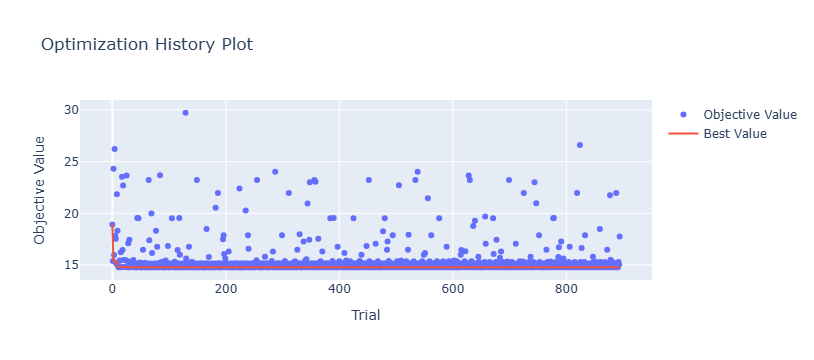

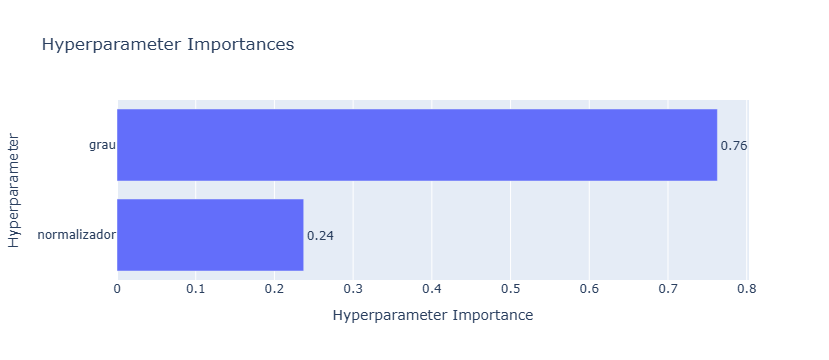

In [39]:
estudo_polinomial = cria_estudo("regressão_polinomial")

if len(estudo_polinomial.trials) == 0:
    estudo_polinomial.enqueue_trial(
        {"normalizador": "padrao", "grau": 2, "num_componentes_grau2": 10}
    )

otimiza(estudo_polinomial, cria_modelo_polinomial)
mostra_resultados(estudo_polinomial)

Foram realizadas 895 tentativas. Dessas, o melhor conjunto de hiperparâmetros encontrado utiliza a normalização por mínimos e máximos, polinômio de grau 2 com 40 componentes; além disso, o RMSE da validação foi de 14.784K. O hiperparâmetro com maior importância para o modelo é o grau do polinômio, mas visto 40 componentes era o teto para polinômios do segundo grau, não é possível separar o grau do polinômio do número de componentes, não sendo possível concluir se é melhor um polinômio do segundo, terceiro ou quarto grau por possuirem tetos diferentes.

É possível perceber que a otimiação do modelo de regressão polinomial gerou resultados melhores do que a regressão linear e que o primeiro modelo polinomial de referência. Por tanto, os termos não lineares geram melhora.

## Modelo de k vizinhos mais próximos (k-NN)

O k-NN prevê o target de um exemplo pela média do target dos seus k vizinhos mais próximos no conjunto de treino. Esse modelo se baseia na hipótese de que os dados são similares aos dados próximos.

### Definição do modelo

Modelos k-NN dependem das distâncias entre os dados, portanto os atributos precisam estar na mesma escala; sem isso, os atributos de maiores dimensões dominariam o cálculo.

Para efeitos comparativos, fora feitos modelos k-NN de referência sem normalização e com a normalização padrão.

Esses modelos, o normalizado e o não normalizado, foram definidos com a função "KNeighborsRegressor" do "scikit-learn".

In [40]:
modelos_knn = {
    "k-NN sem normalização": KNeighborsRegressor(
        n_neighbors=5, n_jobs=-1
    ),
    "k-NN com normalização padrão": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
    ),
}

### Avaliação

Em seguida, os modelos foram avaliados nos conjuntos de treino e de validação.

In [41]:
for nome, modelo in modelos_knn.items():
    RMSE_treino, RMSE_val = avalia_treino_validacao(modelo)
    print(f'{nome}')
    print(f'RMSE no treino: {RMSE_treino:.2f}K')
    print(f'RMSE na validação: {RMSE_val:.2f}K')
    print()

RESULTADOS_PADRAO["k-NN"] = avalia_treino_validacao(modelos_knn["k-NN sem normalização"])

k-NN sem normalização
RMSE no treino: 9.64K
RMSE na validação: 12.23K

k-NN com normalização padrão
RMSE no treino: 8.85K
RMSE na validação: 11.11K



Nota-se que os modelos k-NN obtiveram menos erro que as regressões linear e poliomial. Além disso, o k-NN com a normalização apresentou melhores resultados que o modelo sem ser normalizado. 

### Otimização de hiperparâmetros com o Optuna

Os hiperparâmetros escolhidos para o modelo k-NN foram o tipo de normalização, o uso ou não de PCA e o número de componentes, o número de vizinhos, o peso dos vizinhos e a métrica de distância a ser usada, dentre as métricas de distância Euclidiana, Manhattan e Chebyshev.

**Justificativa dos intervalos: k-NN**

| Hiperparâmetro | Espaço de busca | Justificativa do intervalo |
|---|---|---|
| `num_vizinhos` | 1 a 81 | 1 é o extremo de menor viés, 5 é o valor padrão do `scikit-learn` e o teto de 81 permite modelos bem mais suavizados. |
| `pesos` | `uniform` ou `distance` | Testa se vizinhos mais próximos devem ter mais peso na previsão. |
| `metrica_distancia` | `euclidean`, `manhattan` ou `chebyshev` | A distância Euclidiana perde interesse em muitas dimensões, e o conjunto tem 81 atributos, o que justifica incluir a Manhattan. A Chebyshev completa as três funções de distância comparadas. |

In [42]:
def cria_modelo_knn(trial):
    etapas = []

    normalizador = escolher_normalizador(trial)
    if normalizador is not None:
        etapas.append(normalizador)

    if trial.suggest_categorical("usar_pca", [True, False]):
        num_componentes = trial.suggest_int("num_componentes", 1, len(ATRIBUTOS))
        etapas.append(PCA(n_components=num_componentes, random_state=8888))

    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 81),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metrica_distancia", ["euclidean", "manhattan", "chebyshev"]),
        "n_jobs": -1,
    }
    etapas.append(KNeighborsRegressor(**parametros))
    return make_pipeline(*etapas)

Tentativas realizadas: 112
Conjuntos de hiperparâmetros distintos: 100
Tempo de otimização: 1.7 min

Número do melhor trial: 35
RMSE de validação do melhor trial: 9.883 K
Parâmetros do melhor trial:
  normalizador: padrao
  usar_pca: False
  num_vizinhos: 5
  pesos: distance
  metrica_distancia: manhattan


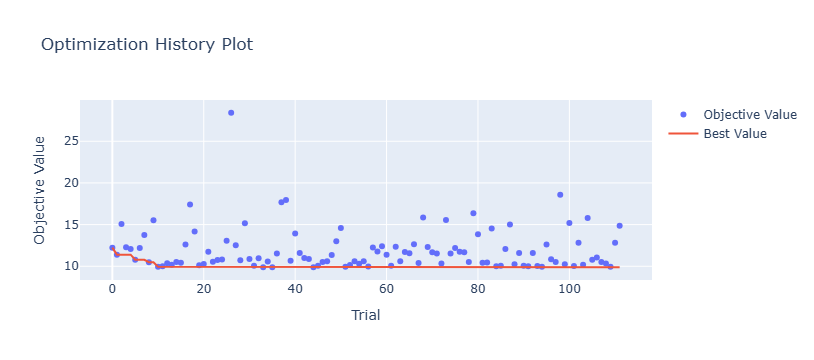

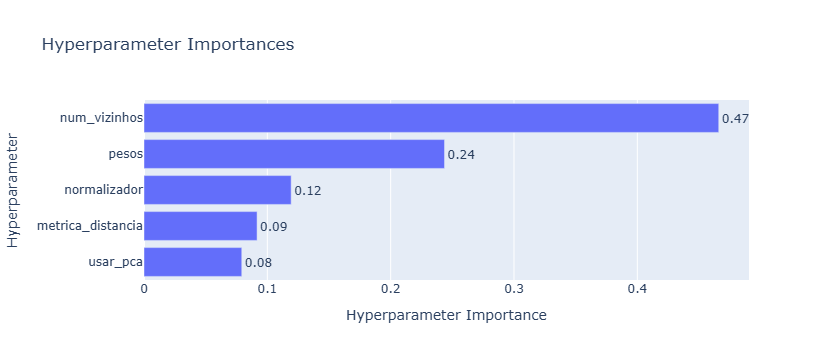

In [43]:
estudo_knn = cria_estudo("knn_tipo_distancia")

if len(estudo_knn.trials) == 0:
    
    padrao_knn = {
        "usar_pca": False,
        "num_vizinhos": 5,
        "pesos": "uniform",
        "tipo_distancia": "euclidiana",
    }
    estudo_knn.enqueue_trial({**padrao_knn, "normalizador": "nenhum"})
    estudo_knn.enqueue_trial({**padrao_knn, "normalizador": "padrao"})

otimiza(estudo_knn, cria_modelo_knn)
mostra_resultados(estudo_knn)

Foram realizadas 112 tentativas. Com isso, o melhor conjunto de hiperparâmetros encontrado foi com a normalização padrão, sem uso de PCA, com o número de vizinhos mais próximos igual a 5, peso pela distância e a métrica de distância Manhattan; com RMSE da validação de 9.883K. O número de vizinhos exerce maior importância, porém os outros hiperparâmetros também apresentaram grande influência sobre o modelo, com destaque aos pesos atribuidos aos vizinhos.

Percebe-se que o erro aqui é menor que o erro da validação dos modelos anteriores e que os modelos k-NN de referência.

## Modelo de árvore de decisão

A árvore de decisão regressora divide sucessivamente os exemplos com regras de decisão sobre os atributos, e a previsão de cada folha é a média do target dos exemplos de treino que chegam a ela.

### Definição do modelo

Árvores de decisão não calculam distâncias entre os exemplos, pois as suas regras de decisão não dependem da escala dos atributos; então, não foi aplicada normalização aos dados originais. Porém, a PCA é possível como etapa de tratamento de dados; quando o Optuna escolhe usá-la, a árvore passa a trabalhar com as componentes principais, e o normalizador aplicado antes da PCA também é um hiperparâmetro.

Para fazer esse modelo, usou-se a função "DecisionTreeRegressor" da biblioteca "scikit-learn".

In [44]:
modelo_arvore_decisao = DecisionTreeRegressor(random_state=8888)
modelo_arvore_decisao.fit(X_treino_, y_treino_)

print(f"Profundidade da árvore sem restrições: {modelo_arvore_decisao.get_depth()}")
print(f"Número de folhas da árvore sem restrições: {modelo_arvore_decisao.get_n_leaves()}")

Profundidade da árvore sem restrições: 36
Número de folhas da árvore sem restrições: 10432


Sem restrições, a árvore atinge a profundidade de 36, com 10432 folhas; uma profundidade muito grande.

### Avaliação

O próximo passo foi a avaliação do modelo de árvore de decisão nos conjuntos de dados de treino e validação.

In [45]:
RMSE_treino, RMSE_val = avalia_treino_validacao(modelo_arvore_decisao)
RESULTADOS_PADRAO["Árvore de decisão"] = (RMSE_treino, RMSE_val)

print(f"RMSE no treino: {RMSE_treino:.2f}K")
print(f"RMSE na validação: {RMSE_val:.2f}K")

RMSE no treino: 4.35K
RMSE na validação: 12.91K


O erro do modelo é, até o momento maior que o modelo k-NN; portanto, sem otimização, não apresenta uma melhora significativa.

### Otimização de hiperparâmetros com o Optuna

Os hiperparâmetros escolhidos para o modelo de árvore de decisão foram o uso ou não de PCA, o tipo de normalização e o número de componentes caso haja uso de PCA, a profundidade máxima, o número máximo de folhas, o mínimo de exemplos para o split e o mínimo de exemplos por folha; os três últimos em escala logarítmica.

**Justificativa dos intervalos: árvore de decisão**

| Hiperparâmetro | Espaço de busca | Justificativa do intervalo |
|---|---|---|
| `profundidade_maxima` | 3 a 60 | A árvore sem restrições atingiu profundidade 36, então 60 inclui o caso de "sem limite efetivo". O piso de 3 corresponde a uma árvore muito rasa. |
| `num_max_folhas` | 10 a 15.000 (log) | O teto é praticamente o número de exemplos de treino, e a árvore sem restrições tinha muitas folhas. O piso de 10 é razoável. A escala logarítmica se justifica porque o intervalo abrange três ordens de grandeza. |
| `min_exemplos_split` | 2 a 50 (log) | O piso é o valor padrão. O teto exige mais dados para dividir um nó. Escala logarítmica se justifica porque o intervalo abrange três ordens de grandeza. |
| `min_exemplos_folha` | 1 a 50 (log) | O piso é o valor padrão. O teto evita folhas que memorizam ruído. Escala logarítmica se justifica porque o intervalo abrange três ordens de grandeza. |

In [46]:
def cria_modelo_arvore(trial):
    etapas = cria_etapas_pca(trial)

    parametros = {
        "max_depth": trial.suggest_int("profundidade_maxima", 3, 60),
        "max_leaf_nodes": trial.suggest_int("num_max_folhas", 10, 15000, log=True),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 50, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 50, log=True),
        "random_state": 8888,
    }
    etapas.append(DecisionTreeRegressor(**parametros))
    return make_pipeline(*etapas)

Tentativas realizadas: 100
Conjuntos de hiperparâmetros distintos: 100
Tempo de otimização: 4.0 min

Número do melhor trial: 57
RMSE de validação do melhor trial: 12.075 K
Parâmetros do melhor trial:
  usar_pca: False
  profundidade_maxima: 21
  num_max_folhas: 1189
  min_exemplos_split: 2
  min_exemplos_folha: 7


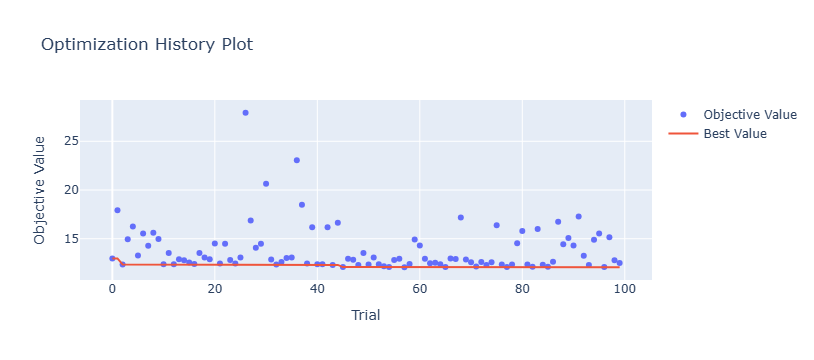

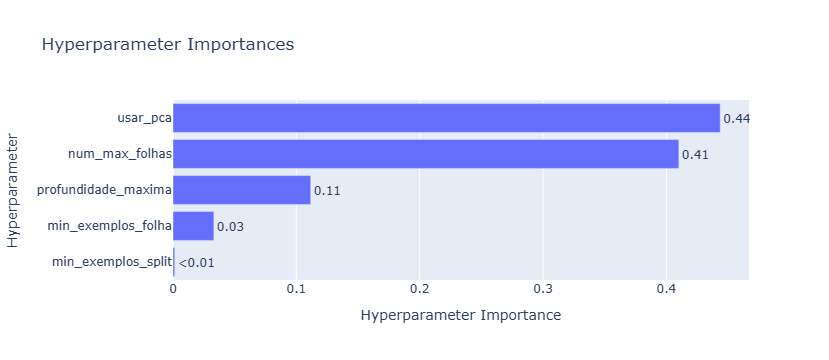

In [47]:
estudo_arvore = cria_estudo("arvore_decisao")

if len(estudo_arvore.trials) == 0:
    
    estudo_arvore.enqueue_trial(
        {
            "usar_pca": False,
            "profundidade_maxima": 60,
            "num_max_folhas": 15000,
            "min_exemplos_split": 2,
            "min_exemplos_folha": 1,
        }
    )

otimiza(estudo_arvore, cria_modelo_arvore)
mostra_resultados(estudo_arvore)

Foram realizadas 100 tentativas. Dessas, o melhor conjunto de hiperparâmetros não usa PCA, contém profundidade máxima de 21, número máximo de folhas igual a 1189, mínimo de exemplos para o split sendo 2 e mínimo de exemplos por folha igual a 7; com RMSE da validação igual a 12.075K. O uso ou não de PCA exerce a maior influência sobre a performace do modelo, porém o número máximo de folhas apresenta influência significativa.

Percebe-se que com o melhor conjunto de hiperparâmetros encontrado, o modelo apresentou erro maior que o modelo k-NN otimizado, sendo o segundo melhor modelo até o momento.

## Modelo de floresta aleatória

O modelo de floresta aleatória consiste em um conjunto de árvores de decisão. Cada árvore é treinada com uma amostra bootstrap, para gerar uma variabilidade e evitar erros pelo acaso. A previsão que é feita é a média das previsões das árvores.

### Definição do modelo

O modelo de floresta aleatória, como o modelo da árvore de decisão, não usa das distâncias para realizar a regressão. Porém, quando o Optuna opta pelo usa de PCA, a normalização antes da PCA é um hiperparâmetro a ser escolhido.

Como modelo de referência, foi feita uma floresta com 100 árvores e o máximo de variávais (features) de 0.33.

Esse modelo foi definido com a função "RandomForestRegressor" da biblioteca "scikit-learn".

In [48]:
modelo = RandomForestRegressor(
    n_estimators=100,
    max_features=0.33,
    n_jobs=-1,
    random_state=8888,
)

### Avaliação

O passo seguinte foi avaliar o modelo nos conjuntos de dados de treino e de validação.

In [49]:
RMSE_treino, RMSE_val = avalia_treino_validacao(modelo)
RESULTADOS_PADRAO["Floresta aleatória"] = (RMSE_treino, RMSE_val)

print(f"RMSE no treino: {RMSE_treino:.2f} K")
print(f"RMSE na validação: {RMSE_val:.2f} K")

RMSE no treino: 5.22 K
RMSE na validação: 9.40 K


O modelo, sem otimização, já apresenta o menor erro dentre os modelos, pois o RMSE nos dados de treino foi de 5.22K e nos dados de treino foi de 9.4K. Essa diferença de RMSE nos dados de treino e validação podem indicar algum tipo de overfitting.

### Otimização de hiperparâmetros com o Optuna

Nesse caso, os hiperparâmetros escolhidos foram o uso ou não de PCA, o normalizador e o número de componentes caso haja uso de PCA, número de árvores, a profundidade máxima, o mínimo de exemplos para o split, o mínimo de exemplos por folha e o número máximo de atributos. Em adição, o bootstrap foi mantido.

**Justificativa dos intervalos: floresta aleatória**

| Hiperparâmetro | Espaço de busca | Justificativa do intervalo |
|---|---|---|
| `num_arvores` | 20 a 100 (log) | O teto é o valor padrão e limita o tempo de otimização, já que a floresta é o modelo mais custoso de treinar. |
| `profundidade_maxima` | 5 a 60 | Mesma lógica da árvore de decisão; a árvore sem restrições atingiu profundidade 36, então 60 equivale a "sem limite efetivo". |
| `min_exemplos_split` | 2 a 20 | Intervalo razoável, e o piso é o valor padrão. |
| `min_exemplos_folha` | 1 a 20 | Intervalo razoável, e o piso é o valor padrão. |
| `num_max_atributos` | 0,1 a 0,5 | 0,33 é um valor que usualmente leva a bom desempenho, e ele está no interior do intervalo. Com 81 atributos, o intervalo equivale a cerca de 8 a 40 atributos por divisão. |
| `bootstrap` | `True` (fixo) | É o valor padrão, que costuma ser uma boa escolha. |

In [50]:
def cria_modelo_floresta(trial):
    etapas = cria_etapas_pca(trial)

    parametros = {
        "n_estimators": trial.suggest_int("num_arvores", 20, 100, log=True),
        "max_depth": trial.suggest_int("profundidade_maxima", 5, 60),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("num_max_atributos", 0.1, 0.5),
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": 8888,
    }
    etapas.append(RandomForestRegressor(**parametros))
    return make_pipeline(*etapas)

Tentativas realizadas: 100
Conjuntos de hiperparâmetros distintos: 100
Tempo de otimização: 9.8 min

Número do melhor trial: 91
RMSE de validação do melhor trial: 9.389 K
Parâmetros do melhor trial:
  usar_pca: False
  num_arvores: 96
  profundidade_maxima: 56
  min_exemplos_split: 3
  min_exemplos_folha: 1
  num_max_atributos: 0.36734562321106246


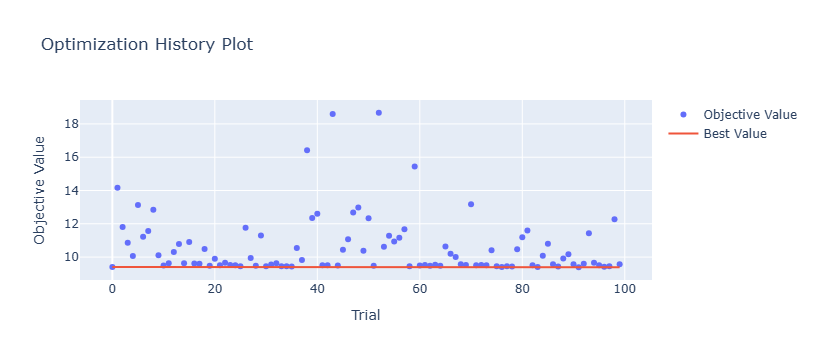

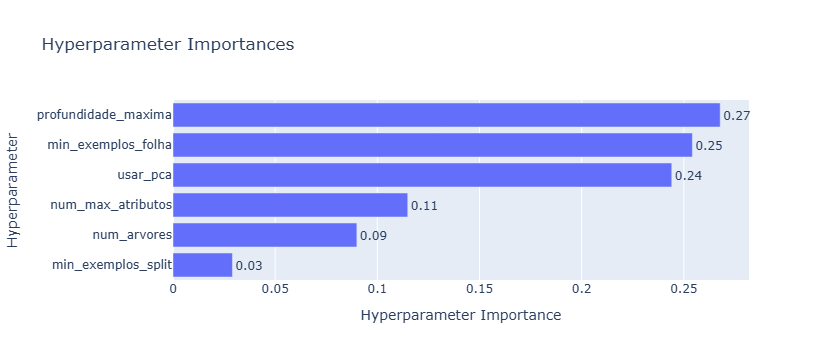

In [51]:
estudo_floresta = cria_estudo("floresta_aleatoria")

if len(estudo_floresta.trials) == 0:
    
    estudo_floresta.enqueue_trial(
        {
            "usar_pca": False,
            "num_arvores": 100,
            "criterio": "squared_error",
            "profundidade_maxima": 60,
            "min_exemplos_split": 2,
            "min_exemplos_folha": 1,
            "num_max_atributos": 0.33,
        }
    )

otimiza(estudo_floresta, cria_modelo_floresta)
mostra_resultados(estudo_floresta)

Foram realizadas 100 tentativas. O melhor conjunto de hiperparâmetros encontrados para a floresta aleatória não usa PCA, possui 96 árvores, com profundidade máxima de 56, mínimo de exemplos para o split igual a 3, número mínimo de exemplos por folha sendo 1, e número máximo de atributos igual a 0.37; comi isso, o RMSE de validação foi de 9.389K. A profundidade máxima é o hiperparâmetro com maior influência sobre o modelo; além dele, o número mínimo de exemplos por folha é influente, já os outros hiperparâmetros geram alterações significativas, apesar de menor que esses dois anteriores.

O erro foi menor que o do modelo k-NN, sendo o melhor modelo avaliado. 

## Redução de dimensionalidade com PCA

A análise de componentes principais (PCA) projeta os dados em novas direções, as componentes principais, que concentram a variância dos dados, permitindo reduzir o número de dimensões e mantendo apenas as primeiras componentes. O número de componentes mantidas é um hiperparâmetro, e a PCA pode ser benéfica em alguns problemas e não em outros, o que só pode ser descoberto testando. Como o conjunto de dados tem 81 atributos muito correlacionados, a PCA se apresenta como uma ferramenta com grande potêncial de otimização.

A seguir, um gráfico que expõe a variância acumulada pela PCA.

Componentes necessárias para explicar 90% da variância: 12
Componentes necessárias para explicar 95% da variância: 17
Componentes necessárias para explicar 99% da variância: 31


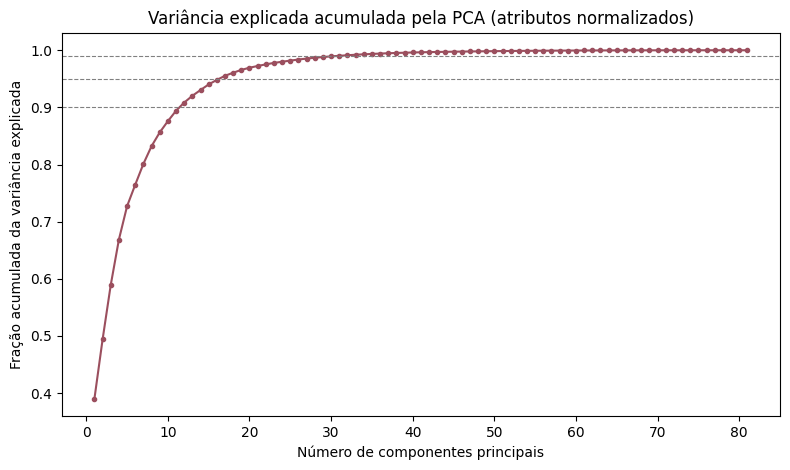

In [52]:
pca_completa = make_pipeline(StandardScaler(), PCA(random_state=8888))
pca_completa.fit(X_treino)

variancia_acumulada = np.cumsum(pca_completa[-1].explained_variance_ratio_)
numeros_de_componentes = np.arange(1, len(variancia_acumulada) + 1)

for fracao in (0.90, 0.95, 0.99):
    n = int(np.argmax(variancia_acumulada >= fracao)) + 1
    print(f"Componentes necessárias para explicar {fracao:.0%} da variância: {n}")

figura, eixo = plt.subplots(figsize=(8, 4.8))
eixo.plot(numeros_de_componentes, variancia_acumulada, marker="o", markersize=3, color="#9B4F5E")
for fracao in (0.90, 0.95, 0.99):
    eixo.axhline(fracao, color="gray", linestyle="--", linewidth=0.8)
eixo.set(
    title="Variância explicada acumulada pela PCA (atributos normalizados)",
    xlabel="Número de componentes principais",
    ylabel="Fração acumulada da variância explicada",
)
figura.tight_layout()
plt.show()

É possível perceber que com 12 componentes, 90% da variância é explicada; já com 31 componentes, 99% da variância é explicada. Isso confirma que os atributos são muito redundantes, como visto na análise de correlação, e que a PCA poderia reduzir bastante a dimensionalidade. Resta saber se isso melhora os modelos, informação adquirida por testes com o Optuna.

Em sequência, para cada modelo, foi comparado o melhor RMSE de validação encontrado entre as tentativas que não usaram a PCA e entre as que usaram, além de mostrar se o melhor trial usa a PCA e com quantos componentes. A regressão polinomial sempre usa a PCA, então não tem tentativas sem PCA.

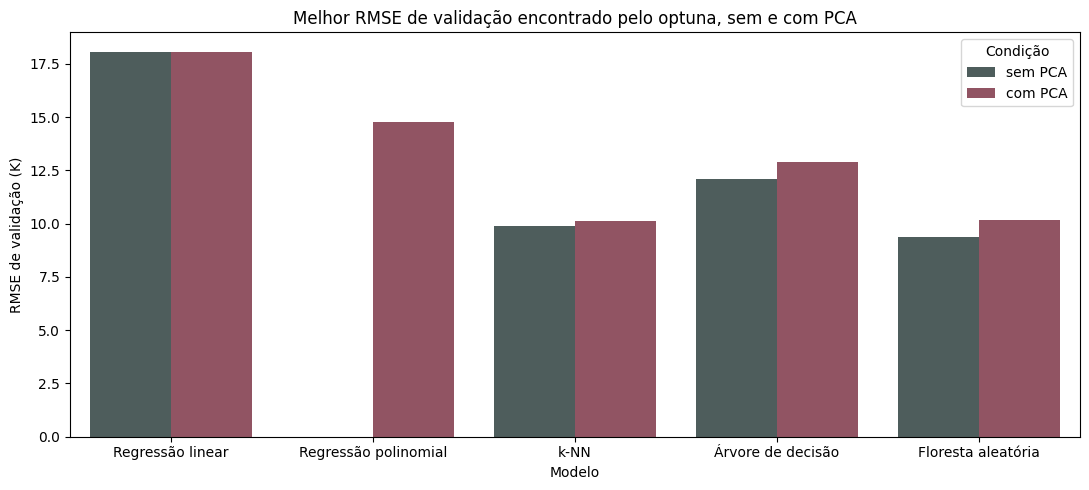

,Melhor RMSE sem PCA (K),Melhor RMSE com PCA (K),Melhor trial usa PCA,Componentes do melhor trial,Tentativas com PCA (%)
Modelo,,,,,
Regressão linear,18.07,18.07,False,NaN,5.94
Regressão polinomial,NaN,14.78,True,40.0,100.00
k-NN,9.88,10.13,False,NaN,26.79
Árvore de decisão,12.08,12.87,False,NaN,26.00
Floresta aleatória,9.39,10.17,False,NaN,27.00


In [53]:
estudos = {
    "Regressão linear": (estudo_linear, cria_modelo_linear),
    "Regressão polinomial": (estudo_polinomial, cria_modelo_polinomial),
    "k-NN": (estudo_knn, cria_modelo_knn),
    "Árvore de decisão": (estudo_arvore, cria_modelo_arvore),
    "Floresta aleatória": (estudo_floresta, cria_modelo_floresta),
}


def componentes_do_trial(parametros):
    """Número de componentes principais de um trial (None se não usou PCA)."""
    if not parametros.get("usar_pca", True):
        return None
    if "num_componentes" in parametros:
        return parametros["num_componentes"]
    return parametros[f"num_componentes_grau{parametros['grau']}"]


linhas = []
for nome, (estudo, _) in estudos.items():
    tabela = estudo.trials_dataframe()
    tabela = tabela[tabela["value"].notna()]

    if "params_usar_pca" in tabela:
        usou_pca = tabela["params_usar_pca"].astype(bool)
    else:  # a regressão polinomial sempre usa PCA
        usou_pca = pd.Series(True, index=tabela.index)

    melhor = estudo.best_trial.params
    linhas.append(
        {
            "Modelo": nome,
            "Melhor RMSE sem PCA (K)": tabela.loc[~usou_pca, "value"].min(),
            "Melhor RMSE com PCA (K)": tabela.loc[usou_pca, "value"].min(),
            "Melhor trial usa PCA": componentes_do_trial(melhor) is not None,
            "Componentes do melhor trial": componentes_do_trial(melhor),
            "Tentativas com PCA (%)": 100 * usou_pca.mean(),
        }
    )

resumo_pca = pd.DataFrame(linhas).set_index("Modelo")

rmse_pca = resumo_pca[["Melhor RMSE sem PCA (K)", "Melhor RMSE com PCA (K)"]].reset_index().melt(
    id_vars="Modelo", var_name="Condição", value_name="RMSE"
)
rmse_pca["Condição"] = rmse_pca["Condição"].str.replace("Melhor RMSE ", "").str.replace(" (K)", "", regex=False)

figura, eixo = plt.subplots(figsize=(11, 5))
sns.barplot(
    data=rmse_pca, x="Modelo", y="RMSE", hue="Condição",
    palette=["#4B5F5E", "#9B4A5E"], ax=eixo,
)
eixo.set(
    title="Melhor RMSE de validação encontrado pelo optuna, sem e com PCA",
    xlabel="Modelo",
    ylabel="RMSE de validação (K)",
)    
figura.tight_layout()
plt.show()

resumo_pca.round(2)

A regressão polinomial é o único modelo que sempre usa a PCA, por necessidade; pois, sem ela, o polinômio teria milhares de atributos; além disso, o seu melhor resultado usou 40 componentes, o limite superior do intervalo. Nos outros quatro modelos, o melhor resultado sem PCA foi igual ou melhor que o melhor resultado com PCA. Em consequência, o Optuna foi abandonando a PCA nesses modelos, que realizaram poucas tentativas, e nenhum dos melhores modelos usa a PCA. Portanto, apesar de poucas componentes explicarem a maior parte da variância e de os atributos serem muito correlacionados, a PCA não melhorou o desempenho dos modelos que podem usar todos os atributos.

## Validação cruzada

Para comparar os modelos para além do desempenho no conjunto de validação, foi feita a validação cruzada k-fold, com 5 folds e apenas no conjunto de treino. Esse número de folds foi escolhido por ser um número que equilibra baixo viés e e variância. Os folds foram definidos usando a função "GroupKFold" da biblioteca "scikit-learn", para que exemplos redundantes ou quase redundantes não fiquem em folds diferentes.

Cada modelo foi avaliado com os melhores hiperparâmetros encontrados pelo Optuna, e o baseline foi incluído como referência. O RMSE de cada fold é calculado com a função "cross_val_score", também da biblioteca "scikit-learn".

In [54]:
modelos_finais = {"Baseline (média)": DummyRegressor(strategy="mean")}
for nome, (estudo, cria_instancia_modelo) in estudos.items():
    modelos_finais[nome] = cria_instancia_modelo(estudo.best_trial)

validacao_cruzada = GroupKFold(n_splits=5)

rmse_por_fold = {}
for nome, modelo in modelos_finais.items():
    metricas = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        groups=grupos_treino,
        cv=validacao_cruzada,
        scoring="neg_root_mean_squared_error",
    )
    rmse_por_fold[nome] = -metricas

rmse_por_fold = pd.DataFrame(rmse_por_fold)
rmse_por_fold.index = [f"Fold {i}" for i in range(1, 6)]
rmse_por_fold.round(2)

,Baseline (média),Regressão linear,Regressão polinomial,k-NN,Árvore de decisão,Floresta aleatória
Fold 1,34.85,17.84,14.56,10.17,12.04,9.78
Fold 2,33.41,17.45,14.91,9.97,12.06,9.46
Fold 3,33.88,17.79,14.71,9.45,11.50,8.90
Fold 4,33.72,17.87,14.57,10.18,12.45,9.41
Fold 5,35.06,17.80,14.80,10.75,12.96,10.18


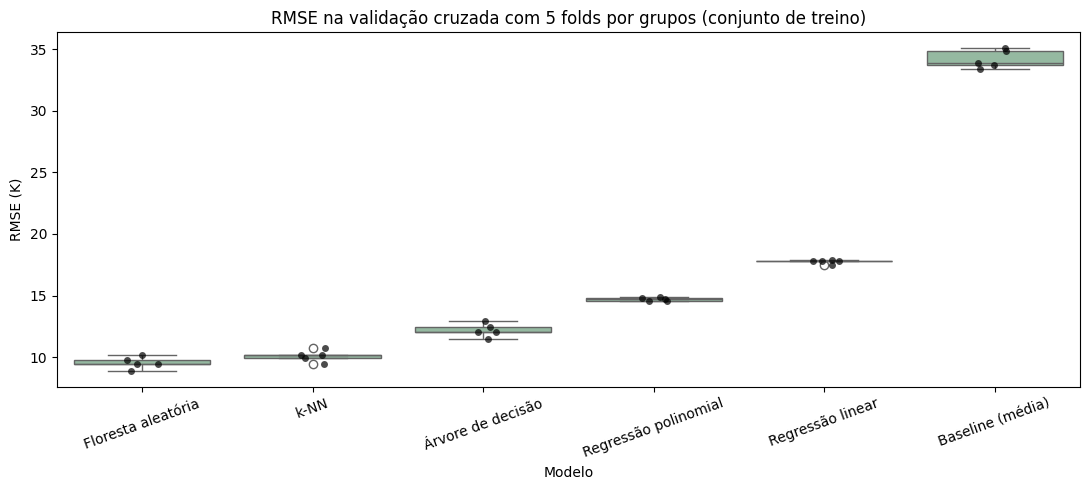

In [55]:
ordem = rmse_por_fold.mean().sort_values().index.tolist()
rmse_longo = rmse_por_fold.melt(var_name="Modelo", value_name="RMSE")

figura, eixo = plt.subplots(figsize=(11, 5))
sns.boxplot(data=rmse_longo, x="Modelo", y="RMSE", order=ordem, ax=eixo, color="#8FBF9F")
sns.stripplot(
    data=rmse_longo, x="Modelo", y="RMSE", order=ordem, ax=eixo,
    color="black", size=5, alpha=0.7,
)
eixo.set(
    title=f"RMSE na validação cruzada com {5} folds por grupos (conjunto de treino)",
    xlabel="Modelo",
    ylabel="RMSE (K)",
)
eixo.tick_params(axis="x", rotation=20)
figura.tight_layout()
plt.show()

É possível notar pela validação cruzada que o melhor modelo proposto foi, de fato, o da floresta aleatória, apresentando o menor média do conjunto de RMSEs dos 5 folds. 

## Comparação dos modelos

A tabela abaixo reúne, para cada modelo, o RMSE de validação com hiperparâmetros padrão e otimizados, o RMSE médio na validação cruzada, o número de conjuntos de hiperparâmetros testados, o tempo de otimização e se o melhor trial usa a PCA. O gráfico compara os três RMSE de cada modelo.

In [56]:
resumos = {nome: resumo_do_estudo(estudo) for nome, (estudo, _) in estudos.items()}

tabela_comparacao = pd.DataFrame(
    {
        "RMSE padrão na validação (K)": pd.Series(
            {nome: RESULTADOS_PADRAO[nome][1] for nome in modelos_finais}
        ),
        "RMSE otimizado na validação (K)": pd.Series(
            {nome: r["Melhor RMSE de validação (K)"] for nome, r in resumos.items()}
        ),
        "RMSE médio na validação cruzada (K)": rmse_por_fold.mean(),
        "Desvio padrão na validação cruzada (K)": rmse_por_fold.std(),
        "Conjuntos de hiperparâmetros distintos": pd.Series(
            {nome: r["Conjuntos distintos"] for nome, r in resumos.items()}
        ),
        "Tempo de otimização (min)": pd.Series(
            {nome: r["Tempo de otimização (min)"] for nome, r in resumos.items()}
        ),
        "Melhor trial usa PCA": resumo_pca["Melhor trial usa PCA"],
    }
).sort_values("RMSE médio na validação cruzada (K)")

nome_vencedor = tabela_comparacao.drop(index="Baseline (média)")[
    "RMSE médio na validação cruzada (K)"
].idxmin()

print(f"Modelo com menor RMSE médio na validação cruzada: {nome_vencedor}")
print("Hiperparâmetros:", estudos[nome_vencedor][0].best_trial.params)

tabela_comparacao.round(2)

Modelo com menor RMSE médio na validação cruzada: Floresta aleatória
Hiperparâmetros: {'usar_pca': False, 'num_arvores': 96, 'profundidade_maxima': 56, 'min_exemplos_split': 3, 'min_exemplos_folha': 1, 'num_max_atributos': 0.36734562321106246}


,RMSE padrão na validação (K),RMSE otimizado na validação (K),RMSE médio na validação cruzada (K),Desvio padrão na validação cruzada (K),Conjuntos de hiperparâmetros distintos,Tempo de otimização (min),Melhor trial usa PCA
Floresta aleatória,9.40,9.39,9.55,0.47,100.0,9.79,False
k-NN,12.23,9.88,10.10,0.47,100.0,1.74,False
Árvore de decisão,12.91,12.08,12.20,0.54,100.0,4.03,False
Regressão polinomial,18.92,14.78,14.71,0.15,100.0,2.18,True
Regressão linear,18.07,18.07,17.75,0.17,100.0,0.34,False
Baseline (média),34.83,NaN,34.18,0.73,NaN,NaN,NaN


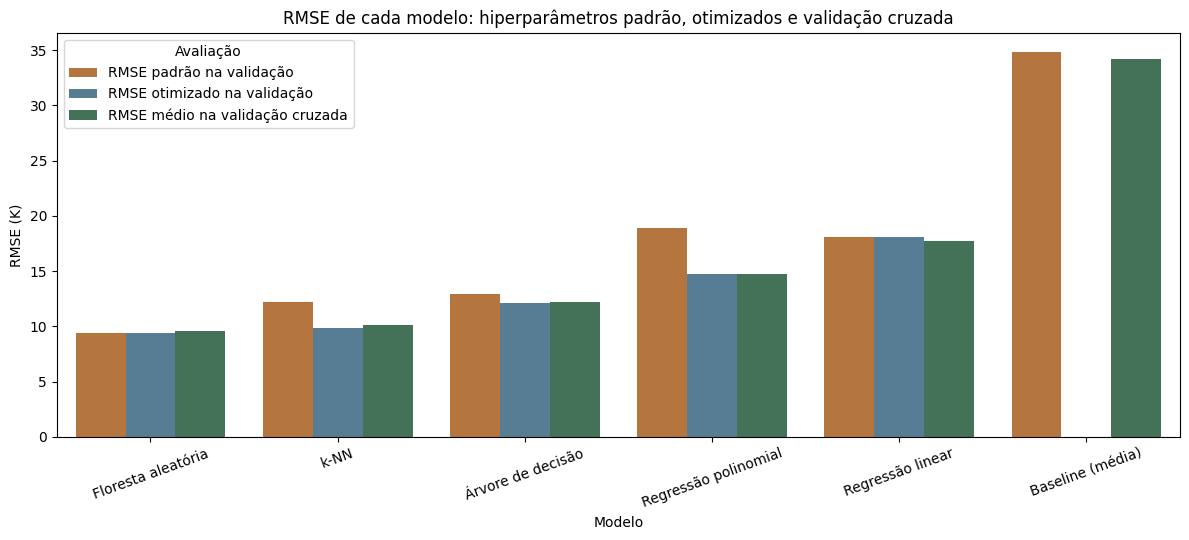

In [57]:
comparacao_longa = tabela_comparacao[
    ["RMSE padrão na validação (K)", "RMSE otimizado na validação (K)", "RMSE médio na validação cruzada (K)"]
].rename(columns=lambda c: c.replace(" (K)", "")).reset_index(names="Modelo").melt(
    id_vars="Modelo", var_name="Avaliação", value_name="RMSE"
)

figura, eixo = plt.subplots(figsize=(12, 5.5))
sns.barplot(
    data=comparacao_longa, x="Modelo", y="RMSE", hue="Avaliação",
    palette=["#C8742B", "#4C7F9E", "#3B7A57"], ax=eixo,
)
eixo.set(
    title="RMSE de cada modelo: hiperparâmetros padrão, otimizados e validação cruzada",
    xlabel="Modelo",
    ylabel="RMSE (K)",
)
eixo.tick_params(axis="x", rotation=20)
figura.tight_layout()
plt.show()

Com a tabela e o gráfico, nota-se que todos os modelos reduzem o erro do baseline, mas em graus muito diferentes. Os modelos não lineares e mais flexíveis (k-NN, árvore de decisão e floresta aleatória) são claramente melhores que os modelos lineares, o que é coerente com a relação não linear sugerida na análise exploratória.

## Validação final no conjunto de teste

Para não haver vazamento de dados, o conjunto de teste foi usado apenas na validação final, após os hiperparâmetros terem sido otimizados e de o melhor modelo ter sido escolhido na validação cruzada. Cada modelo foi treinado novamente com todo o conjunto de treino e com os melhores hiperparâmetros encontrados, e o RMSE no teste de todos os modelos é apresentado para mostrar o desempenho esperado em dados novos.

In [58]:
modelos_treinados = {}
linhas = []

for nome, modelo in modelos_finais.items():
    modelo.fit(X_treino, y_treino)
    modelos_treinados[nome] = modelo
    linhas.append(
        {
            "Modelo": nome,
            "RMSE no treino (K)": root_mean_squared_error(y_treino, modelo.predict(X_treino)),
            "RMSE no teste (K)": root_mean_squared_error(y_teste, modelo.predict(X_teste)),
            "RMSE médio na validação cruzada (K)": tabela_comparacao.loc[
                nome, "RMSE médio na validação cruzada (K)"
            ],
        }
    )

resultados_teste = pd.DataFrame(linhas).set_index("Modelo").loc[tabela_comparacao.index]

modelo_final = modelos_treinados[nome_vencedor]
y_previsto = modelo_final.predict(X_teste)
RMSE_teste = resultados_teste.loc[nome_vencedor, "RMSE no teste (K)"]
RMSE_baseline_teste = resultados_teste.loc["Baseline (média)", "RMSE no teste (K)"]

print(f"Modelo escolhido pela validação cruzada: {nome_vencedor}")
print(f"RMSE do modelo escolhido no teste: {RMSE_teste:.2f} K")
print(f"RMSE do baseline no teste: {RMSE_baseline_teste:.2f} K")
print(f"Redução do erro em relação ao baseline: {1 - RMSE_teste / RMSE_baseline_teste:.1%}")

resultados_teste.round(2)

Modelo escolhido pela validação cruzada: Floresta aleatória
RMSE do modelo escolhido no teste: 9.76 K
RMSE do baseline no teste: 34.86 K
Redução do erro em relação ao baseline: 72.0%


,RMSE no treino (K),RMSE no teste (K),RMSE médio na validação cruzada (K)
Floresta aleatória,5.10,9.76,9.55
k-NN,4.45,10.68,10.10
Árvore de decisão,7.39,12.48,12.20
Regressão polinomial,13.69,14.85,14.71
Regressão linear,17.56,17.63,17.75
Baseline (média),34.18,34.86,34.18


É perceptível que O RMSE no conjunto de teste obteve ordem de grandeza próximo ao da validação cruzada, mostrando que a avaliação por validação cruzada foi confiável. O modelo escolhido foi o da floresta aleatória, que mais uma vez obteve o menor erro.

## Explicabilidade do modelo escolhido

O modelo escolhido, uma floresta aleatória com dezenas de árvores profundas, é uma "caixa-preta": não dá para ler suas regras como se lê uma regressão linear. Esta seção usa ferramentas de explicação para investigar o que o modelo aprendeu e se isso faz sentido para o problema.

O modelo final já está fixo e o conjunto de teste não foi usado para escolher nada. Por isso, usar o teste aqui apenas para explicar o modelo não gera vazamento de dados, uma vez que as explicações não alteram o modelo nem os hiperparâmetros.

Serão usadas duas ferramentas: importância por impureza, que soma, em todas as árvores, da melhora local de desempenho de cada divisão que usa o atributo. É calculada com os dados de treino e costuma favorecer atributos com muitos valores distintos; e importância por permutação; que embaralha uma coluna do conjunto de teste, o que destrói a relação dela com o target, e mede-se quanto o RMSE aumenta, quanto maior o aumento, mais o modelo dependia daquele atributo, sendo repetido várias vezes e reportando a média e o desvio padrão. 

Os 81 atributos são 10 estatísticas de cada uma de 8 propriedades elementares, então muitos são redundantes. Ao embaralhar uma coluna isolada, o modelo pode recuperar a informação por meio de colunas correlacionadas e a importância parece pequena. Por isso, além da permutação individual, será feita uma permutação agrupada, em que todas as colunas do grupo são embaralhadas juntas, com a mesma permutação de linhas.

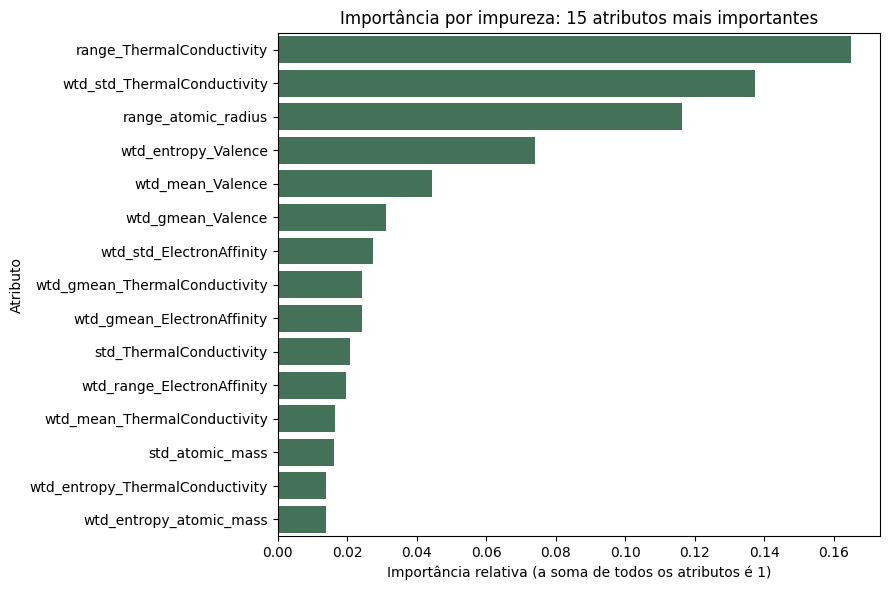

In [59]:
assert nome_vencedor == "Floresta aleatória" and not any(
    isinstance(etapa, PCA) for _, etapa in modelo_final.steps
), "A explicação por atributo assume uma floresta aleatória sem PCA."

importancia_impureza = pd.Series(
    modelo_final[-1].feature_importances_, index=ATRIBUTOS
).sort_values(ascending=False)

mais_importantes = importancia_impureza.head(15)

figura, eixo = plt.subplots(figsize=(9, 6))
sns.barplot(x=mais_importantes.values, y=mais_importantes.index, color="#3B7A57", ax=eixo)
eixo.set(
    title="Importância por impureza: 15 atributos mais importantes",
    xlabel="Importância relativa (a soma de todos os atributos é 1)",
    ylabel="Atributo",
)
figura.tight_layout()
plt.show()

### Importância por permutação

Aqui o RMSE do modelo final é medido no conjunto de teste após embaralhar cada atributo, 10 vezes por atributo. A barra mostra o aumento médio do RMSE e a linha preta mostra o desvio padrão entre as 10 repetições.

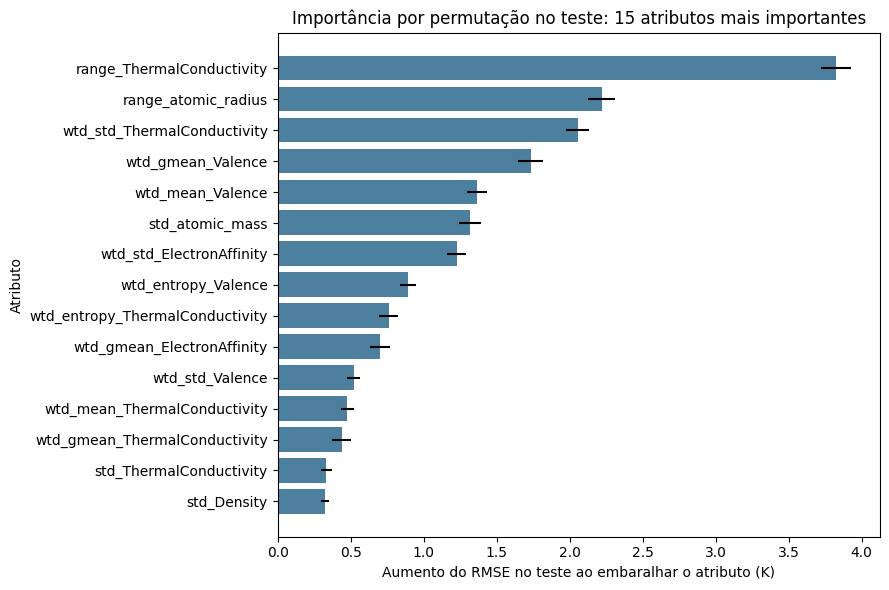

In [60]:
resultado_permutacao = permutation_importance(
    modelo_final,
    X_teste,
    y_teste,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=8888,
    n_jobs=-1,
)

importancia_permutacao = pd.DataFrame(
    {
        "aumento_medio_rmse": resultado_permutacao.importances_mean,
        "desvio_padrao": resultado_permutacao.importances_std,
    },
    index=ATRIBUTOS,
).sort_values("aumento_medio_rmse", ascending=False)

mais_importantes = importancia_permutacao.head(15)

figura, eixo = plt.subplots(figsize=(9, 6))
eixo.barh(
    mais_importantes.index[::-1],
    mais_importantes["aumento_medio_rmse"][::-1],
    xerr=mais_importantes["desvio_padrao"][::-1],
    color="#4C7F9E",
    ecolor="black",
)
eixo.set(
    title="Importância por permutação no teste: 15 atributos mais importantes",
    xlabel="Aumento do RMSE no teste ao embaralhar o atributo (K)",
    ylabel="Atributo",
)
figura.tight_layout()
plt.show()

Os atributos no topo da importância por permutação são, em sua maioria, estatísticas da condutividade térmica, da valência e do raio atômico. A importância por impureza aponta para o mesmo grupo de atributos no topo, com ordem um pouco diferente, o que é esperado.

### Importância por permutação agrupada

Como as 80 colunas de propriedades elementares vêm em grupos, todas as colunas de um grupo são embaralhadas juntas, com a mesma permutação de linhas, o que preserva as relações entre elas e remove só a relação com o target. O atributo "number_of_elements" forma um grupo próprio na análise por estatística.

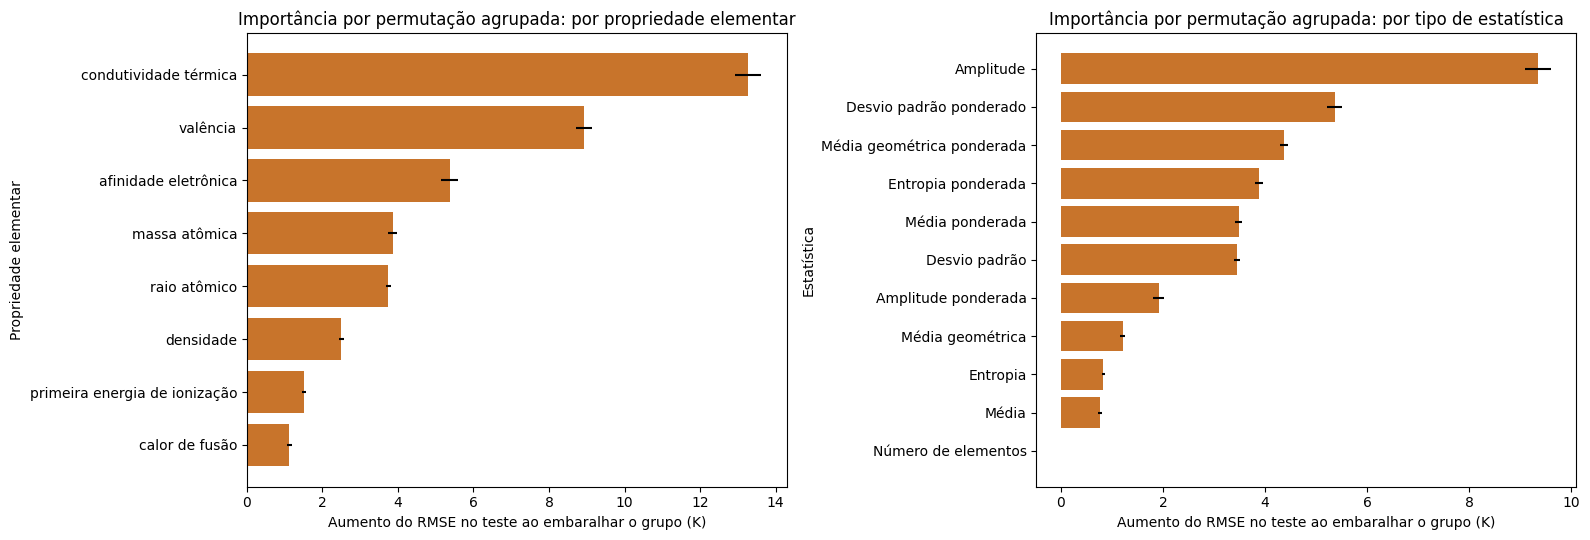

In [61]:
def importancia_agrupada(modelo, X, y, grupos_de_colunas, num_repeticoes=10, semente=8888):
    """Aumento do RMSE ao embaralhar, juntas, todas as colunas de cada grupo."""
    gerador = np.random.default_rng(semente)
    rmse_base = root_mean_squared_error(y, modelo.predict(X))
    resultados = {}

    for nome_grupo, colunas in grupos_de_colunas.items():
        indices = [ATRIBUTOS.index(coluna) for coluna in colunas]
        aumentos = []
        for _ in range(num_repeticoes):
            X_embaralhado = X.copy()
            permutacao = gerador.permutation(len(X))
            X_embaralhado[:, indices] = X[permutacao][:, indices]
            aumentos.append(root_mean_squared_error(y, modelo.predict(X_embaralhado)) - rmse_base)
        resultados[nome_grupo] = (np.mean(aumentos), np.std(aumentos))

    return (
        pd.DataFrame(resultados, index=["aumento_medio_rmse", "desvio_padrao"])
        .T.sort_values("aumento_medio_rmse", ascending=False)
    )


grupos_por_propriedade = {
    nome: [f"{estatistica}_{chave}" for estatistica in estatisticas]
    for chave, nome in propriedades.items()
}
grupos_por_estatistica = {
    nome: [f"{chave}_{propriedade}" for propriedade in propriedades]
    for chave, nome in estatisticas.items()
}
grupos_por_estatistica["Número de elementos"] = ["number_of_elements"]

importancia_por_propriedade = importancia_agrupada(modelo_final, X_teste, y_teste, grupos_por_propriedade)
importancia_por_estatistica = importancia_agrupada(modelo_final, X_teste, y_teste, grupos_por_estatistica)

figura, eixos = plt.subplots(1, 2, figsize=(16, 5.5))
for eixo, tabela, titulo, rotulo_y in [
    (eixos[0], importancia_por_propriedade, "Por propriedade elementar", "Propriedade elementar"),
    (eixos[1], importancia_por_estatistica, "Por tipo de estatística", "Estatística"),
]:
    eixo.barh(tabela.index[::-1], tabela["aumento_medio_rmse"][::-1],
              xerr=tabela["desvio_padrao"][::-1], color="#C8742B", ecolor="black")
    eixo.set(
        title=f"Importância por permutação agrupada: {titulo.lower()}",
        xlabel="Aumento do RMSE no teste ao embaralhar o grupo (K)",
        ylabel=rotulo_y,
    )
figura.tight_layout()
plt.show()

Por propriedade, a condutividade térmica é a que mais pesa para o modelo, seguida pela valência. Em um segundo bloco ficam afinidade eletrônica, raio atômico e massa atômica, e densidade, primeira energia de ionização e calor de fusão têm importância menor. Por estatística, a amplitude (máximo menos mínimo entre os elementos do composto) é a mais usada, seguida por estatísticas ponderadas pela proporção de cada elemento (desvio padrão, média geométrica, média e entropia). Isso sugere que o modelo se apoia mais em quão diferentes entre si são os elementos do composto do que na média simples da propriedade.

Com essas três análises, é possível notar que os atributos que mais geram alterações no modelo são relacionados à condutividade térmica, à valência e ao raio atômico.

## Conclusões e principais aprendizados

O objetivo do presente trabalho consistia na aplicação dos conteúdos aprendidos nas aulas da disciplina de Aprendizado de Máquina. Para isso, foram desenvolvidos algoritmos com o objetivo de prever a temperatura crítica de materiais supercondutores a partir de 81 atributos calculados da fórmula química. Foram comparados cinco modelos: regressão linear, regressão polinomial, k-NN, árvore de decisão e floresta aleatória, além de um baseline, todos seguindo os modelos, métricas e ferramentas dos notebooks da disciplina, com pelo menos 100 conjuntos distintos de hiperparâmetros testados em cada modelo com o Optuna, incluindo o uso da PCA. A floresta aleatória foi o melhor modelo na validação cruzada, com RMSE de 9,57 K, e teve RMSE de 9,77 K no conjunto de teste, contra 34,86 K do baseline, uma redução de 72% do erro.

Os principais aprendizados foram a identificação e o tratamento de dados redundantes e quase redundantes, com o uso do método de agrupamento, evitando o vazamento de dados; o uso e comparação de diferentes modelos, tal qual o modo com que operam, seu hiperparâmetros, influência da normalização e do uso de PCA para redução de dimensionalidade, dentre outros aspectos envolvendo os diferentes modelos usados; o uso do Optuna para a otimização dos modelos e intervalos de teste de hiperparâmetros; o uso de PCA para a redução de dimensionalidade e otimização dos modelos, tal qual seu controle pelo Optuna; divisão em dados de treino, teste e validação para avaliar modelos; método de validação cruzada para comparar os modelos; e a importância de explicar um modelo.

## Descrição do uso de IA

O uso de Inteligência Artificial nesse projeto envolveu a busca do conjunto de dados, esclarecimento de dúvidas sobre o conteúdo, planejamento do projeto, auxilio com a ordem lógica de apresentação do projeto, correções em erros de código, correção de erros gramaticais, auxilio com a produção de gráficos, debates sobre estratégias interessantes e resultados obtidos, aconselhamento do espaço de busca do Optuna, dos hiperparâmetros e limites, formatação das referências e revisão final do projeto.

## Referências

[1] HAMIDIEH, Kam. Superconductivty Data [conjunto de dados]. Irvine: UCI Machine Learning Repository, 2018. Disponível em: https://archive.ics.uci.edu/dataset/464/superconductivty+data. Acesso em: 21 set. 2026.

[2] CASSAR, Daniel R. ATP-203 1.1 - Tratamento de dados com pandas. 2026. Jupyter Notebook. Material didático não publicado.

[3] CASSAR, Daniel R. ATP-203 2.1 - Aprendizado de máquina: k-NN e métricas. 2026. Jupyter Notebook. Material didático não publicado.

[4] CASSAR, Daniel R. ATP-203 2.2 - Divisão de dados em treino e teste. 2026. Jupyter Notebook. Material didático não publicado.

[5] CASSAR, Daniel R. ATP-203 3.0 - Modelo linear e baseline. 2026. Jupyter Notebook. Material didático não publicado.

[6] CASSAR, Daniel R. ATP-203 4.0 - Árvore de decisão e floresta aleatória. 2026. Jupyter Notebook. Material d6idático não publicado.

[7] CASSAR, Daniel R. ATP-203 6.0 - Validação cruzada e otimização de hiperparâmetros. 2026. Jupyter Notebook. Material didático não publicado.

[8] CASSAR, Daniel R. ATP-203 6.1 - Vazamento de dados. 2026. Jupyter Notebook. Material didático não publicado.

[9] CASSAR, Daniel R. ATP-203 7.0 - Dados sintéticos e pipeline. 2026. Jupyter Notebook. Material didático não publicado.

[10] CASSAR, Daniel R. ATP-203 7.1 - Otimização de hiperparâmetros com optuna. 2026. Jupyter Notebook. Material didático não publicado.

[11] CASSAR, Daniel R. ATP-203 8.0 - Redução de dimensionalidade com PCA. 2026. Jupyter Notebook. Material didático não publicado.

[12] CASSAR, Daniel R. ATP-203 8.1 - Seleção de atributos. 2026. Jupyter Notebook. Material didático não publicado.

[13] SCIKIT-LEARN. Documentação do scikit-learn. Disponível em: https://scikit-learn.org/stable/. Acesso em: 15 out. 2026.

[14] OPTUNA. Documentação do Optuna. Disponível em: https://optuna.readthedocs.io/en/stable/. Acesso em: 30 out. 2026.